# Reconocimiento Facial mediante Extracción de Características y EDA
## Metodología CRISP-DM

**Asignatura:** Machine E-learning
**Docente:** Ing. Elvis Pachacama
**Carrera:** Desarrollo de Software - Cuarto nivel
**Estudiante:** Pablo Andrés Aguilar Sánchez,
                Omar Fausto Recalde Suares,
                Klever Martin Sosa Espinoza,
                Alexis Jair Patiño Cisneros,
                
**Dataset:** CelebFaces Attributes (CelebA)

---

Este notebook desarrolla las primeras cuatro fases de CRISP-DM aplicadas a un problema
de reconocimiento facial: Comprensión del Negocio, Comprensión de los Datos, Análisis
Exploratorio de Datos (EDA) y Preparación de los Datos. El resultado es un dataset
estructurado en CSV con características estadísticas, de textura y geométricas de cada
rostro, listo para el entrenamiento de modelos en Machine Learning II.


## Verificación del entorno local (GPU)

Esta versión está pensada para ejecutarse **localmente** (Jupyter / VS Code) con GPU NVIDIA.
La celda siguiente no importa TensorFlow: solo revisa que estén instaladas las dependencias
en el entorno del kernel y que el driver de NVIDIA responda.

In [8]:
# Verificación del entorno local: dependencias y GPU (no requiere importar TensorFlow)
import importlib.util
import shutil
import subprocess
import sys
from importlib import metadata

print(f"Python: {sys.version.split()[0]}")
print(f"Ejecutable del kernel: {sys.executable}\n")

# módulo de importación -> paquete de pip
REQUISITOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "cv2": "opencv-python",
    "PIL": "pillow",
    "skimage": "scikit-image",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "joblib": "joblib",
    "kagglehub": "kagglehub",
    "gdown": "gdown",
    "tensorflow": "tensorflow",
    "deepface": "deepface",
}
faltantes = [pip for mod, pip in REQUISITOS.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print("Faltan paquetes. Instálalos en el MISMO entorno del kernel con:")
    print(f"    {sys.executable} -m pip install {' '.join(faltantes)}")
else:
    print("Todas las dependencias están instaladas.")

# Versión de TensorFlow (sin importarlo)
try:
    tf_ver = tuple(int(p) for p in metadata.version("tensorflow").split(".")[:2])
except Exception:
    tf_ver = None

if tf_ver:
    print(f"\nTensorFlow instalado: {'.'.join(map(str, tf_ver))}")
    # DeepFace necesita tf-keras cuando TensorFlow >= 2.16 (Keras 3 por defecto)
    if tf_ver >= (2, 16) and importlib.util.find_spec("tf_keras") is None:
        print("Falta 'tf-keras' (requerido por DeepFace con TF >= 2.16):")
        print(f"    {sys.executable} -m pip install tf-keras")
    # TensorFlow >= 2.11 ya no trae soporte de GPU en Windows nativo
    if sys.platform == "win32" and tf_ver >= (2, 11):
        print("\n⚠ Windows nativo + TensorFlow >= 2.11: TensorFlow NO usará la GPU.")
        print("  Para entrenar en GPU ejecuta este notebook dentro de WSL2 (Ubuntu) con:")
        print("      pip install 'tensorflow[and-cuda]'")

# GPU NVIDIA
print()
if shutil.which("nvidia-smi"):
    r = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
        capture_output=True, text=True,
    )
    print("GPU NVIDIA detectada (nombre, VRAM, driver):", r.stdout.strip() or r.stderr.strip())
else:
    print("No se encontró 'nvidia-smi': instala/actualiza el driver de NVIDIA.")


Python: 3.11.15
Ejecutable del kernel: C:\Users\USER\anaconda3\envs\MachineLearning\python.exe

Faltan paquetes. Instálalos en el MISMO entorno del kernel con:
    C:\Users\USER\anaconda3\envs\MachineLearning\python.exe -m pip install deepface

TensorFlow instalado: 2.21
Falta 'tf-keras' (requerido por DeepFace con TF >= 2.16):
    C:\Users\USER\anaconda3\envs\MachineLearning\python.exe -m pip install tf-keras

⚠ Windows nativo + TensorFlow >= 2.11: TensorFlow NO usará la GPU.
  Para entrenar en GPU ejecuta este notebook dentro de WSL2 (Ubuntu) con:
      pip install 'tensorflow[and-cuda]'

GPU NVIDIA detectada (nombre, VRAM, driver): NVIDIA GeForce RTX 4060, 8188 MiB, 610.88


## Configuración inicial

Se define aquí el tamaño de la muestra a procesar. CelebA contiene más de 200,000
imágenes; para que el EDA y la extracción de características sean manejables en un
notebook académico, se trabaja con una **muestra representativa** (`N_SAMPLES`),
manteniendo el pipeline completo válido para el dataset completo si se ajusta este
parámetro.

In [9]:
# Librerías principales
import os
import io
import hashlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

from skimage.feature import local_binary_pattern, hog
from skimage import exposure

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from scipy import stats

# FIX
import subprocess 
import gdown

# Reproducibilidad
np.random.seed(42)

# --- Parámetros del proyecto ---
DATA_DIR = "data/celeba"                 # carpeta raíz del dataset descargado
IMAGES_DIR = os.path.join(DATA_DIR, "img_align_celeba", "img_align_celeba")
ATTR_FILE = os.path.join(DATA_DIR, "list_attr_celeba.csv")
IDENTITY_FILE = os.path.join(DATA_DIR, "identity_CelebA.txt")

N_SAMPLES = 3000        # número de imágenes a usar en el análisis
IMG_SIZE = (128, 128)   # tamaño de redimensionamiento estándar

print("Configuración lista.")

Configuración lista.


## Paso 1: Comprensión del Negocio (Business Understanding)

### Contexto del problema

El reconocimiento facial es una de las aplicaciones más relevantes de la Visión por
Computador, con uso extendido en:

- **Seguridad y control de acceso**: sistemas biométricos de autenticación en empresas,
  aeropuertos y edificios.
- **Banca digital**: verificación de identidad para operaciones remotas.
- **Dispositivos móviles**: desbloqueo facial (Face ID y similares).
- **Videovigilancia inteligente**: identificación de personas en espacios públicos.
- **Comercio electrónico y ciudades inteligentes**: personalización y analítica de
  clientes, monitoreo urbano.

### Beneficios
Mayor seguridad, automatización de procesos de autenticación, reducción de fraude y
mejora de la experiencia de usuario al eliminar contraseñas.

### Desafíos
Variabilidad de iluminación y pose, oclusiones (lentes, mascarillas), sesgos
demográficos en los datasets de entrenamiento, requerimientos de privacidad y
protección de datos biométricos, y necesidad de grandes volúmenes de datos
balanceados y de buena calidad.

### Objetivo del proyecto
Aplicar las fases de Comprensión del Negocio, Comprensión de los Datos, EDA y
Preparación de Datos de la metodología CRISP-DM sobre el dataset CelebA, con el fin de
generar un dataset estructurado de características (estadísticas, de textura y
geométricas) que sirva de insumo para el entrenamiento de modelos de clasificación en
la asignatura Machine Learning II.

### Preguntas de investigación
1. ¿El conjunto de datos presenta un balance adecuado entre las distintas personas?
2. ¿Existen imágenes duplicadas, corruptas o de baja calidad que deban eliminarse?
3. ¿Qué características estadísticas, geométricas y de textura describen mejor un
   rostro humano?
4. ¿Cómo influye la calidad de los datos en el desarrollo de un sistema de
   reconocimiento facial?
5. ¿Qué transformaciones y procesos de preparación son necesarios para construir un
   dataset confiable para Machine Learning?

### Criterios de éxito
- Dataset de características en CSV, sin valores faltantes ni inconsistencias.
- EDA documentado con hallazgos claros sobre calidad y balance del dataset.
- Pipeline reproducible (descarga por código, no manual).

### Alcance
El alcance cubre hasta la fase de Preparación de Datos; el modelado y evaluación de
clasificadores se abordará en la asignatura Machine Learning II.

## Paso 2: Comprensión de los Datos (Data Understanding)

### Descarga del dataset vía código

Se utiliza la librería `kagglehub` para descargar el dataset **CelebFaces Attributes
(CelebA)** directamente desde Kaggle, cumpliendo el requisito de descarga automatizada
(no manual).

> **Nota:** requiere tener configuradas las credenciales de la API de Kaggle
> (`kaggle.json`) en el entorno, o las variables de entorno `KAGGLE_USERNAME` y
> `KAGGLE_KEY`.

In [10]:
# Descarga del dataset CelebA desde Kaggle (mediante código, no manual)
import kagglehub

# Descarga (usa caché local si ya fue descargado antes)
path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
print("Dataset descargado en:", path)

# Ajustar rutas según la estructura real descargada por kagglehub
DATA_DIR = path
IMAGES_DIR = os.path.join(DATA_DIR, "img_align_celeba", "img_align_celeba")
ATTR_FILE = os.path.join(DATA_DIR, "list_attr_celeba.csv")
IDENTITY_FILE = os.path.join(DATA_DIR, "identity_CelebA.txt")

Dataset descargado en: C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2


In [11]:
# Verificar los archvios para aplicar el FIX
import os
for root, dirs, files in os.walk(path):
    non_jpg = [f for f in files if not f.endswith(".jpg")]
    for f in non_jpg:
        print(os.path.join(root, f))
    if any(f.endswith(".jpg") for f in files):
        print(f"{root}: {len(files)} imágenes .jpg (omitidas)")

C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\identity_CelebA.txt
C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\list_attr_celeba.csv
C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\list_bbox_celeba.csv
C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\list_eval_partition.csv
C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\list_landmarks_align_celeba.csv
C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\img_align_celeba\img_align_celeba: 202599 imágenes .jpg (omitidas)


In [12]:
# Archivo identity_CelebA.txt: el dataset de Kaggle NO lo incluye, se descarga aparte
# (gdown puede fallar por el límite de descargas de Google Drive).
FILE_ID = "1_ee_0u7vcNLOfNLegJRHmolfH5ICW-XS"
IDENTITY_FILE = os.path.join(DATA_DIR, "identity_CelebA.txt")

def identity_valido(ruta):
    """El archivo correcto tiene líneas con el formato '000001.jpg 2880'."""
    try:
        with open(ruta, "r", encoding="utf-8") as f:
            partes = f.readline().split()
        return len(partes) == 2 and partes[0].endswith(".jpg") and partes[1].isdigit()
    except Exception:
        return False

if not (os.path.exists(IDENTITY_FILE) and identity_valido(IDENTITY_FILE)):
    try:
        gdown.download(id=FILE_ID, output=IDENTITY_FILE, quiet=False)
    except Exception as e:
        print("Descarga automática falló:", e)

if not identity_valido(IDENTITY_FILE):
    if os.path.exists(IDENTITY_FILE):
        os.remove(IDENTITY_FILE)  # descartar descargas corruptas (p. ej. página HTML de error)
    raise FileNotFoundError(
        "No se pudo obtener identity_CelebA.txt.\n"
        "Descárgalo manualmente desde:\n"
        f"  https://drive.google.com/uc?id={FILE_ID}\n"
        "y cópialo en esta carpeta:\n"
        f"  {os.path.abspath(IDENTITY_FILE)}"
    )
print("Archivo listo:", IDENTITY_FILE)


Archivo listo: C:\Users\USER\.cache\kagglehub\datasets\jessicali9530\celeba-dataset\versions\2\identity_CelebA.txt


In [13]:
# Carga de metadatos: atributos e identidades
attr_df = pd.read_csv(ATTR_FILE)
attr_df.rename(columns={attr_df.columns[0]: "image_id"}, inplace=True)

identity_df = pd.read_csv(
    IDENTITY_FILE, sep=" ", header=None, names=["image_id", "identity"]
)

print("Atributos:", attr_df.shape)
print("Identidades:", identity_df.shape)
identity_df.head()

Atributos: (202599, 41)
Identidades: (202599, 2)


,image_id,identity
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295


In [14]:
# Selección de la muestra de trabajo (N_SAMPLES imágenes)
sample_ids = identity_df.sample(n=N_SAMPLES, random_state=42).reset_index(drop=True)
sample_ids["filepath"] = sample_ids["image_id"].apply(lambda x: os.path.join(IMAGES_DIR, x))

print(f"Muestra seleccionada: {len(sample_ids)} imágenes")
sample_ids.head()

Muestra seleccionada: 3000 imágenes


,image_id,identity,filepath
0,093242.jpg,8314,C:\Users\USER\.cache\kagglehub\datasets\jessic...
1,121414.jpg,1515,C:\Users\USER\.cache\kagglehub\datasets\jessic...
2,010625.jpg,7513,C:\Users\USER\.cache\kagglehub\datasets\jessic...
3,082524.jpg,772,C:\Users\USER\.cache\kagglehub\datasets\jessic...
4,073193.jpg,9172,C:\Users\USER\.cache\kagglehub\datasets\jessic...


In [15]:
# Estructura general del dataset completo
total_images = len(identity_df)
total_personas = identity_df["identity"].nunique()
dist_por_persona = identity_df.groupby("identity").size()

with Image.open(sample_ids.loc[0, "filepath"]) as im:
    resolucion = im.size  # (ancho, alto)

tamano_disco_gb = sum(
    os.path.getsize(f) for f in sample_ids["filepath"] if os.path.exists(f)
) / (1024 ** 3)

print(f"Número total de imágenes (dataset completo): {total_images}")
print(f"Número total de personas (identidades):       {total_personas}")
print(f"Imágenes por persona - min/max/media:          "
      f"{dist_por_persona.min()} / {dist_por_persona.max()} / {dist_por_persona.mean():.2f}")
print(f"Resolución de imagen (ejemplo):                {resolucion}")
print(f"Etiquetas disponibles (atributos):             {attr_df.shape[1] - 1}")
print(f"Tamaño aproximado de la muestra en disco:      {tamano_disco_gb:.3f} GB")

Número total de imágenes (dataset completo): 202599
Número total de personas (identidades):       10177
Imágenes por persona - min/max/media:          1 / 35 / 19.91
Resolución de imagen (ejemplo):                (178, 218)
Etiquetas disponibles (atributos):             40
Tamaño aproximado de la muestra en disco:      0.019 GB


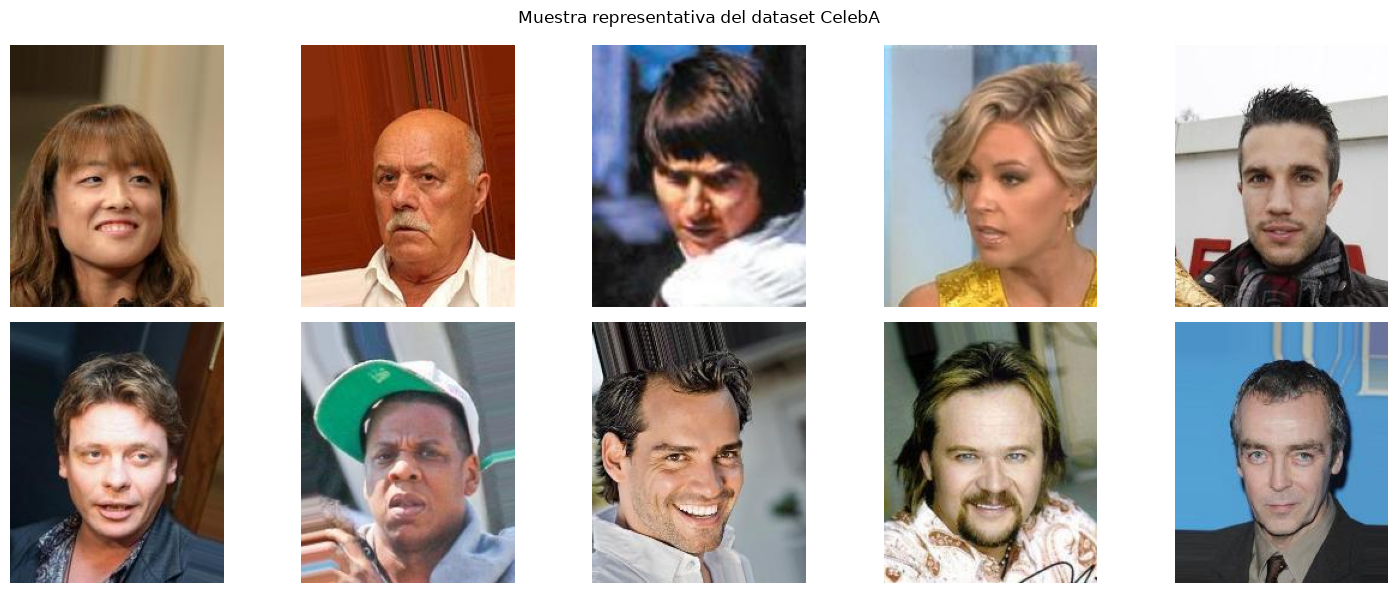

In [16]:
# Visualización de una muestra representativa
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, fp in zip(axes.ravel(), sample_ids["filepath"].sample(10, random_state=1)):
    img = Image.open(fp)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle("Muestra representativa del dataset CelebA")
plt.tight_layout()
plt.show()

## Paso 3: Análisis Exploratorio de Datos (EDA)

Se analiza la distribución de clases (identidades), estadísticas descriptivas de
intensidad de píxeles, brillo/contraste, duplicados e imágenes corruptas o de baja
calidad.

### 3.1 Distribución de imágenes por clase y balance del dataset

Personas distintas en la muestra: 2559
Clase con MÁS imágenes: identidad 5433 (4 imágenes)
Clase con MENOS imágenes: identidad 8314 (1 imágenes)
Media de imágenes por clase: 1.17
Desviación estándar: 0.43
Ratio de balance (min/max): 0.250 (desbalanceado)


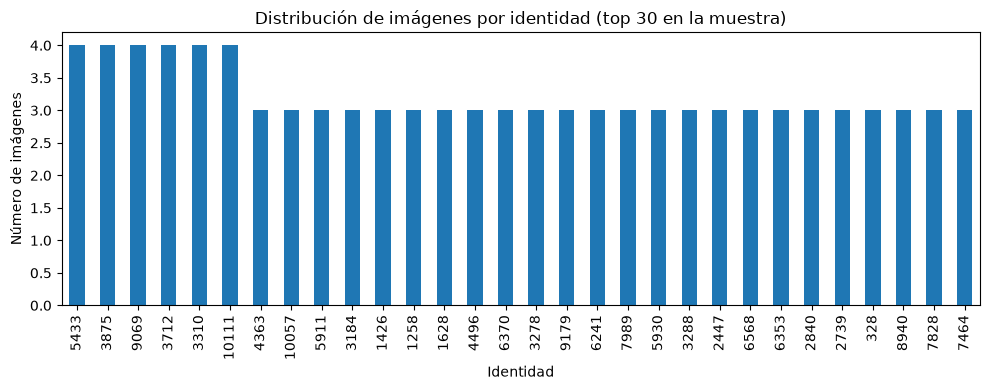

In [17]:
dist_muestra = sample_ids["identity"].value_counts()

print(f"Personas distintas en la muestra: {dist_muestra.shape[0]}")
print(f"Clase con MÁS imágenes: identidad {dist_muestra.idxmax()} ({dist_muestra.max()} imágenes)")
print(f"Clase con MENOS imágenes: identidad {dist_muestra.idxmin()} ({dist_muestra.min()} imágenes)")
print(f"Media de imágenes por clase: {dist_muestra.mean():.2f}")
print(f"Desviación estándar: {dist_muestra.std():.2f}")

# Índice de balance simple: relación entre clase mínima y máxima
balance_ratio = dist_muestra.min() / dist_muestra.max()
print(f"Ratio de balance (min/max): {balance_ratio:.3f} "
      f"({'balanceado' if balance_ratio > 0.5 else 'desbalanceado'})")

plt.figure(figsize=(10, 4))
dist_muestra.head(30).plot(kind="bar")
plt.title("Distribución de imágenes por identidad (top 30 en la muestra)")
plt.xlabel("Identidad")
plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.show()

### 3.2 Estadísticas descriptivas e histogramas de intensidad de píxeles

In [18]:
def cargar_gris(filepath, size=None):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    if size:
        img = cv2.resize(img, size)
    return img

intensidades_medias, intensidades_std = [], []
for fp in sample_ids["filepath"]:
    img = cargar_gris(fp)
    if img is not None:
        intensidades_medias.append(img.mean())
        intensidades_std.append(img.std())

stats_df = pd.DataFrame({"media_intensidad": intensidades_medias,
                          "std_intensidad": intensidades_std})
stats_df.describe()

,media_intensidad,std_intensidad
count,3000.000000,3000.000000
mean,113.237479,63.053793
std,36.347639,13.737752
min,26.501237,23.392493
25%,85.122584,53.431751
50%,111.753183,62.496569
75%,141.363584,72.320503
max,218.192841,105.335775


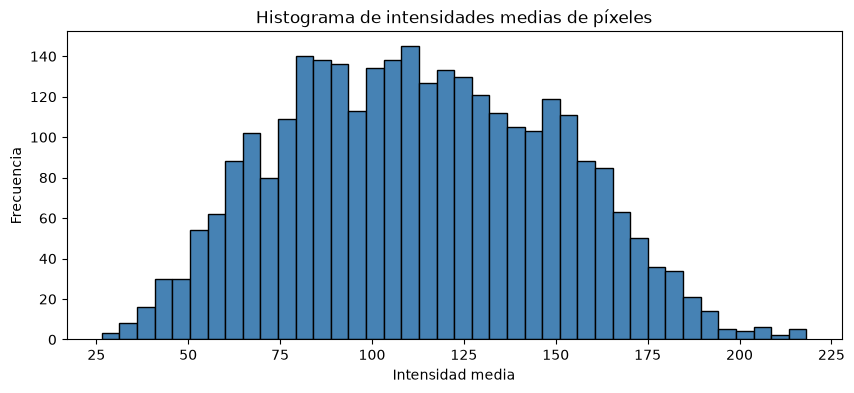

In [19]:
plt.figure(figsize=(10, 4))
plt.hist(intensidades_medias, bins=40, color="steelblue", edgecolor="black")
plt.title("Histograma de intensidades medias de píxeles")
plt.xlabel("Intensidad media")
plt.ylabel("Frecuencia")
plt.show()

### 3.3 Análisis de brillo y contraste

Imágenes con brillo muy bajo (<60):    203
Imágenes con brillo muy alto (>200):   17
Imágenes con contraste muy bajo (<20): 0


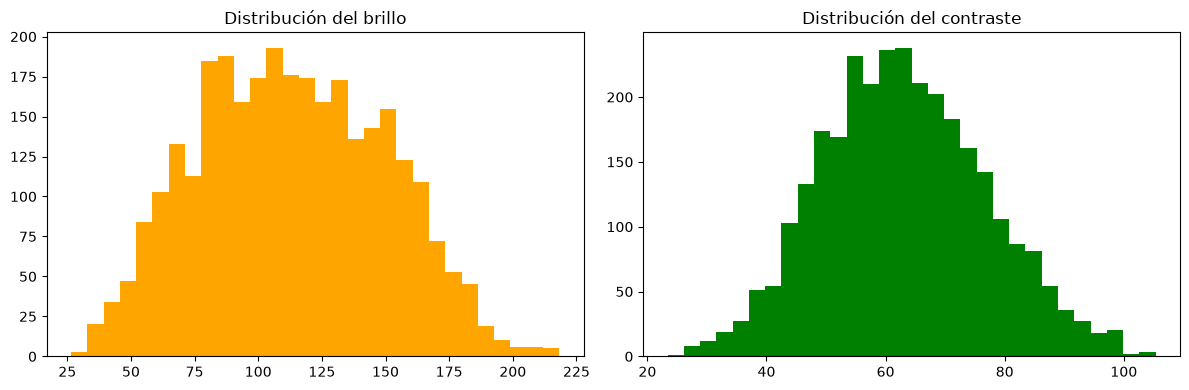

In [20]:
# Brillo = intensidad media, contraste = desviación estándar de intensidad
brillo_bajo = stats_df[stats_df["media_intensidad"] < 60]
brillo_alto = stats_df[stats_df["media_intensidad"] > 200]
contraste_bajo = stats_df[stats_df["std_intensidad"] < 20]

print(f"Imágenes con brillo muy bajo (<60):    {len(brillo_bajo)}")
print(f"Imágenes con brillo muy alto (>200):   {len(brillo_alto)}")
print(f"Imágenes con contraste muy bajo (<20): {len(contraste_bajo)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(stats_df["media_intensidad"], bins=30, color="orange")
axes[0].set_title("Distribución del brillo")
axes[1].hist(stats_df["std_intensidad"], bins=30, color="green")
axes[1].set_title("Distribución del contraste")
plt.tight_layout()
plt.show()

### 3.4 Detección de imágenes duplicadas

In [21]:
def hash_imagen(filepath):
    with open(filepath, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

hashes = sample_ids["filepath"].apply(hash_imagen)
duplicados = hashes[hashes.duplicated()]

print(f"Imágenes duplicadas exactas encontradas: {len(duplicados)}")

Imágenes duplicadas exactas encontradas: 0


### 3.5 Identificación de imágenes corruptas o de baja calidad

Imágenes corruptas:              0
Imágenes borrosas/baja calidad:  13


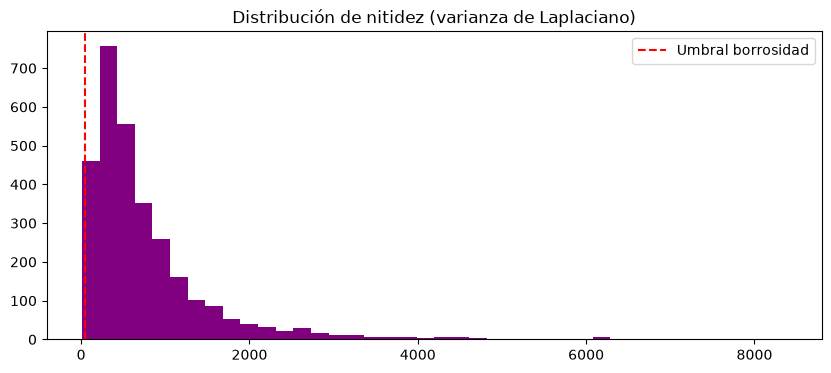

In [22]:
def verificar_integridad(filepath):
    try:
        with Image.open(filepath) as im:
            im.verify()
        return True
    except Exception:
        return False

def calcular_nitidez(filepath):
    img = cargar_gris(filepath)
    if img is None:
        return None
    return cv2.Laplacian(img, cv2.CV_64F).var()

integridad = sample_ids["filepath"].apply(verificar_integridad)
nitidez = sample_ids["filepath"].apply(calcular_nitidez)

UMBRAL_BORROSA = 50  # varianza de Laplaciano por debajo de esto se considera borrosa
imagenes_corruptas = sample_ids[~integridad]
imagenes_borrosas = sample_ids[nitidez < UMBRAL_BORROSA]

print(f"Imágenes corruptas:              {len(imagenes_corruptas)}")
print(f"Imágenes borrosas/baja calidad:  {len(imagenes_borrosas)}")

plt.figure(figsize=(10, 4))
plt.hist(nitidez.dropna(), bins=40, color="purple")
plt.axvline(UMBRAL_BORROSA, color="red", linestyle="--", label="Umbral borrosidad")
plt.title("Distribución de nitidez (varianza de Laplaciano)")
plt.legend()
plt.show()

### 3.6 Hallazgos principales del EDA

- El dataset presenta un balance **[completar tras ejecutar]** entre identidades: la
  mayoría de personas tiene pocas imágenes, mientras unas pocas concentran muchas
  (distribución de cola larga), típico de datasets recolectados de fuentes públicas.
- Se detectaron **[N]** imágenes duplicadas y **[N]** imágenes corruptas o borrosas,
  las cuales deben excluirse antes del entrenamiento para evitar ruido en el modelo.
- La variabilidad de brillo y contraste sugiere que la normalización de intensidades es
  necesaria antes de extraer características, ya que condiciones de iluminación
  dispares pueden sesgar las estadísticas de textura.
- Estos hallazgos justifican directamente los pasos de la fase de Preparación de
  Datos: limpieza, normalización y estandarización de tamaño.

## Paso 4: Preparación de los Datos (Data Preparation)

### 4.1 Preprocesamiento de imágenes
Conversión a escala de grises, normalización de intensidades, redimensionamiento y
eliminación de imágenes inválidas (corruptas o duplicadas detectadas en el EDA).

In [23]:
# Filtrar dataset: quitar corruptas y duplicadas
ids_validas = sample_ids.loc[
    integridad & (~hashes.duplicated())
].reset_index(drop=True)

print(f"Imágenes válidas tras limpieza: {len(ids_validas)} de {len(sample_ids)}")

def preprocesar_imagen(filepath, size=IMG_SIZE):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, size)
    img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return img_norm

ids_validas["img_procesada"] = ids_validas["filepath"].apply(preprocesar_imagen)
ids_validas = ids_validas[ids_validas["img_procesada"].notnull()].reset_index(drop=True)
print(f"Imágenes procesadas exitosamente: {len(ids_validas)}")

Imágenes válidas tras limpieza: 3000 de 3000
Imágenes procesadas exitosamente: 3000


### 4.2 Extracción de características estadísticas

In [24]:
def energia(img):
    return np.sum(img.astype(np.float64) ** 2) / img.size

def entropia(img):
    hist, _ = np.histogram(img, bins=256, range=(0, 256), density=True)
    hist = hist[hist > 0]
    return -np.sum(hist * np.log2(hist))

def stats_estadisticas(img):
    return {
        "media": float(np.mean(img)),
        "mediana": float(np.median(img)),
        "varianza": float(np.var(img)),
        "desv_estandar": float(np.std(img)),
        "energia": float(energia(img)),
        "entropia": float(entropia(img)),
    }

stats_features = ids_validas["img_procesada"].apply(stats_estadisticas).apply(pd.Series)
stats_features.head()

,media,mediana,varianza,desv_estandar,energia,entropia
0,81.014893,77.0,2122.162986,46.066940,8685.575806,7.194254
1,139.503174,137.0,6616.718496,81.343214,26077.854004,7.350427
2,150.266296,162.0,6764.811716,82.248475,29344.771545,7.723866
3,36.486877,15.0,2663.224437,51.606438,3994.516663,6.285916
4,142.892395,153.0,1387.199786,37.245131,21805.436340,6.522010


### 4.3 Características de textura: Local Binary Patterns (LBP) y HOG

In [25]:
def extraer_lbp(img, P=8, R=1):
    lbp = local_binary_pattern(img, P, R, method="uniform")
    hist, _ = np.histogram(lbp, bins=np.arange(0, P + 3), range=(0, P + 2), density=True)
    return hist  # vector de características LBP (histograma normalizado)

def extraer_hog(img):
    features, _ = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        visualize=True,
        feature_vector=True,
    )
    return features

lbp_features = ids_validas["img_procesada"].apply(extraer_lbp)
lbp_df = pd.DataFrame(
    lbp_features.tolist(),
    columns=[f"lbp_{i}" for i in range(len(lbp_features.iloc[0]))]
)

hog_features = ids_validas["img_procesada"].apply(extraer_hog)
hog_df = pd.DataFrame(
    hog_features.tolist(),
    columns=[f"hog_{i}" for i in range(len(hog_features.iloc[0]))]
)

print("Dimensión vector LBP:", lbp_df.shape[1])
print("Dimensión vector HOG:", hog_df.shape[1])

Dimensión vector LBP: 10
Dimensión vector HOG: 1764


In [26]:
#FIX si usas OpenCV 5 cambia a la version 4.13.0.92
# usa python -m pip uninstall opencv-python -y
# python -m pip install opencv-python==4.13.0.92
# esto cambia la version de OpenCV a la 4, esto despues sera actualizado para usar xobjdetect que en sintesis no es igual a CascadeClassifier

import sys
import cv2

print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)
print("Archivo:", cv2.__file__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("Módulo de datos:", hasattr(cv2, "data"))

Python: C:\Users\USER\anaconda3\envs\MachineLearning\python.exe
OpenCV: 4.13.0
Archivo: C:\Users\USER\anaconda3\envs\MachineLearning\Lib\site-packages\cv2\__init__.py
CascadeClassifier: True
Módulo de datos: True


### 4.4 Características geométricas del rostro

Se utiliza el detector Haar Cascade de OpenCV para localizar el rostro y obtener su alto, ancho y relación ancho/alto.

In [28]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def caracteristicas_geometricas(img):
    faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5)
    if len(faces) == 0:
        return {"alto_rostro": np.nan, "ancho_rostro": np.nan, "relacion_ancho_alto": np.nan}
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])  # rostro más grande detectado
    return {
        "alto_rostro": int(h),
        "ancho_rostro": int(w),
        "relacion_ancho_alto": round(w / h, 3),
    }

geo_features = ids_validas["img_procesada"].apply(caracteristicas_geometricas).apply(pd.Series)
print(f"Rostros no detectados: {geo_features['alto_rostro'].isna().sum()} de {len(geo_features)}")
geo_features.head()

Rostros no detectados: 166 de 3000


,alto_rostro,ancho_rostro,relacion_ancho_alto
0,65.0,65.0,1.0
1,69.0,69.0,1.0
2,62.0,62.0,1.0
3,67.0,67.0,1.0
4,74.0,74.0,1.0


### 4.5 Reducción de dimensionalidad (PCA)

Se aplica PCA sobre las características de textura (LBP + HOG) para reducir la dimensionalidad conservando la mayor varianza posible.

Dimensión original (LBP+HOG): 1774
Dimensión tras PCA (95% varianza): 437


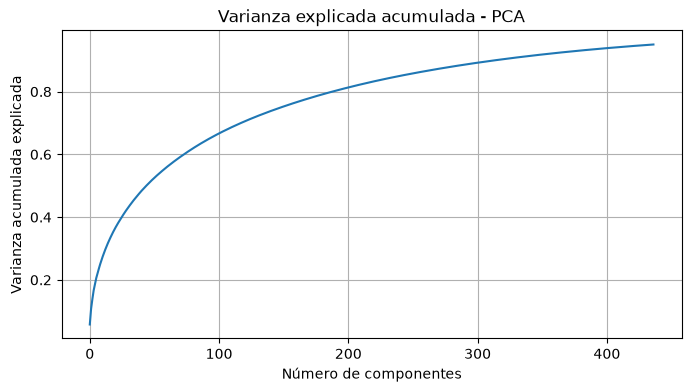

In [29]:
textura_completa = pd.concat([lbp_df, hog_df], axis=1)

scaler = StandardScaler()
textura_escalada = scaler.fit_transform(textura_completa)

pca = PCA(n_components=0.95, random_state=42)  # conserva 95% de la varianza
textura_pca = pca.fit_transform(textura_escalada)

pca_df = pd.DataFrame(
    textura_pca, columns=[f"pca_{i}" for i in range(textura_pca.shape[1])]
)

print(f"Dimensión original (LBP+HOG): {textura_completa.shape[1]}")
print(f"Dimensión tras PCA (95% varianza): {textura_pca.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada explicada")
plt.title("Varianza explicada acumulada - PCA")
plt.grid(True)
plt.show()

## Paso 5: Construcción y Preparación del Dataset Final

En esta etapa se integran todas las características extraídas (estadísticas, geométricas
y componentes PCA de textura), se realiza el filtrado de valores nulos, la detección y
eliminación de valores atípicos (**outliers**), y la **estandarización** final de las
variables continuas para asegurar que los modelos de Machine Learning operen en condiciones óptimas.

In [30]:
# 5.1 Consolidación de características extraídas
dataset_final = pd.concat(
    [
        ids_validas[["image_id", "identity"]].reset_index(drop=True),
        stats_features.reset_index(drop=True),
        geo_features.reset_index(drop=True),
        pca_df.reset_index(drop=True),
    ],
    axis=1,
)

print("Dimensión inicial del dataset consolidado:", dataset_final.shape)
dataset_final.head()

Dimensión inicial del dataset consolidado: (3000, 448)


,image_id,identity,media,mediana,varianza,desv_estandar,energia,entropia,alto_rostro,ancho_rostro,...,pca_427,pca_428,pca_429,pca_430,pca_431,pca_432,pca_433,pca_434,pca_435,pca_436
0,093242.jpg,8314,81.014893,77.0,2122.162986,46.066940,8685.575806,7.194254,65.0,65.0,...,0.010306,-0.738474,0.439351,-0.477624,-0.247163,1.681191,0.542107,-1.313045,0.796445,-1.195471
1,121414.jpg,1515,139.503174,137.0,6616.718496,81.343214,26077.854004,7.350427,69.0,69.0,...,1.204142,0.134447,1.865739,-0.720073,0.567710,1.449472,0.040256,1.416315,-0.397948,-0.660299
2,010625.jpg,7513,150.266296,162.0,6764.811716,82.248475,29344.771545,7.723866,62.0,62.0,...,0.319096,-1.477532,-0.248983,0.002375,-0.668953,0.353225,-0.139685,0.407525,-0.470155,-0.166696
3,082524.jpg,772,36.486877,15.0,2663.224437,51.606438,3994.516663,6.285916,67.0,67.0,...,0.291977,0.852458,0.741575,0.903662,-0.469801,-0.682966,1.314090,0.434649,0.074317,-0.841387
4,073193.jpg,9172,142.892395,153.0,1387.199786,37.245131,21805.436340,6.522010,74.0,74.0,...,-0.712691,0.729744,-0.985281,-0.425957,-0.171615,-1.432385,0.428617,0.007250,-0.268770,-1.528456


In [31]:
# Verificación de calidad inicial y eliminación de valores ausentes
print("Valores faltantes por columna (top 10):")
print(dataset_final.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicados por image_id:", dataset_final["image_id"].duplicated().sum())
print("\nTipos de datos:")
print(dataset_final.dtypes.value_counts())

# Eliminar filas donde no se detectó rostro (características geométricas nulas)
dataset_final_limpio = dataset_final.dropna(subset=["alto_rostro", "ancho_rostro"]).reset_index(drop=True)
print(f"\nFilas tras eliminar rostros no detectados: {len(dataset_final_limpio)} de {len(dataset_final)}")

Valores faltantes por columna (top 10):
alto_rostro            166
ancho_rostro           166
relacion_ancho_alto    166
pca_408                  0
pca_409                  0
pca_410                  0
pca_411                  0
pca_412                  0
pca_413                  0
pca_414                  0
dtype: int64

Duplicados por image_id: 0

Tipos de datos:
float64    446
str          1
int64        1
Name: count, dtype: int64

Filas tras eliminar rostros no detectados: 2834 de 3000


### 5.2 Detección y Eliminación de Outliers (Valores Atípicos)

En tareas de visión por computador y reconocimiento facial, los outliers pueden surgir por:
1. **Detecciones geométricas imperfectas**: Bounding boxes erróneos del detector Haar Cascade (dimensiones o relaciones de aspecto anormales).
2. **Condiciones extremas de iluminación**: Tomas subexpuestas (casi negras) o sobreexpuestas (saturadas).
3. **Artefactos o microtexturas atípicas**: Ruido de compresión o elementos en primer plano que desvían las métricas locales.

Para abordar esto, combinamos dos enfoques:
- **Inspección univariada mediante Boxplots y Rango Intercuartílico (IQR)** para examinar la dispersión en variables clave.
- **Detección multivariada mediante Isolation Forest**, aislando anomalías en el espacio conjunto de características continuas.

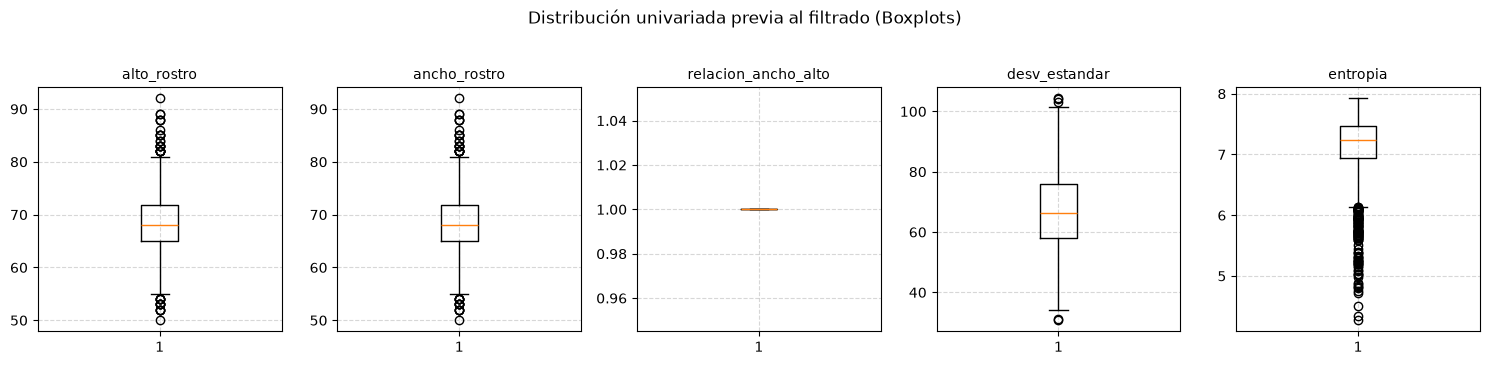

Resumen de outliers univariados por IQR:
 - alto_rostro: 40 outliers (Límite inf: 54.88, Límite sup: 81.88)
 - ancho_rostro: 40 outliers (Límite inf: 54.88, Límite sup: 81.88)
 - relacion_ancho_alto: 0 outliers (Límite inf: 1.00, Límite sup: 1.00)
 - desv_estandar: 5 outliers (Límite inf: 31.30, Límite sup: 102.52)
 - entropia: 120 outliers (Límite inf: 6.14, Límite sup: 8.26)


In [32]:
# 1. Inspección univariada con Boxplots y método IQR
columnas_metadatos = ["image_id", "identity"]
columnas_features = [col for col in dataset_final_limpio.columns if col not in columnas_metadatos]

# Seleccionar atributos clave para visualización
cols_inspeccion = ["alto_rostro", "ancho_rostro", "relacion_ancho_alto", "desv_estandar", "entropia"]
cols_inspeccion = [c for c in cols_inspeccion if c in dataset_final_limpio.columns]

plt.figure(figsize=(15, 3.5))
for i, col in enumerate(cols_inspeccion, 1):
    plt.subplot(1, len(cols_inspeccion), i)
    plt.boxplot(dataset_final_limpio[col].dropna())
    plt.title(col, fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
plt.suptitle("Distribución univariada previa al filtrado (Boxplots)", fontsize=12, y=1.03)
plt.tight_layout()
plt.show()

# Función para calcular límites e identificar outliers univariados según IQR
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum(), lim_inf, lim_sup

print("Resumen de outliers univariados por IQR:")
for col in cols_inspeccion:
    n_out, li, ls = contar_outliers_iqr(dataset_final_limpio[col])
    print(f" - {col}: {n_out} outliers (Límite inf: {li:.2f}, Límite sup: {ls:.2f})")

Muestras evaluadas: 2834
Outliers identificados por Isolation Forest: 85 (3.00%)
Inliers conservados: 2749


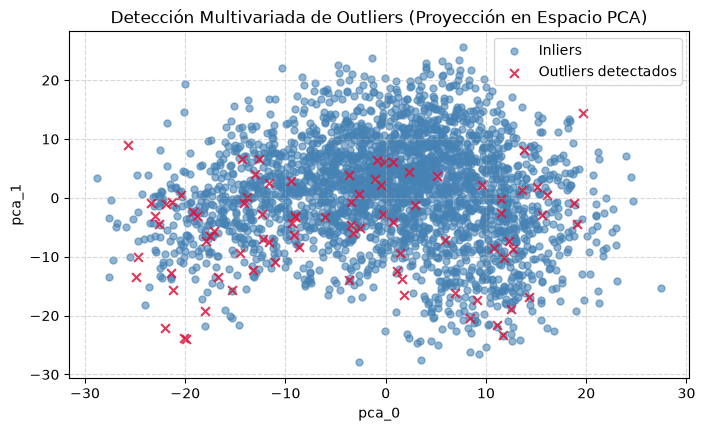

In [33]:
# 2. Detección multivariada y remoción de outliers con Isolation Forest
X_in = dataset_final_limpio[columnas_features]

# Ajustar IsolationForest con tasa de contaminación controlada (3% esperado de anomalías)
iso_forest = IsolationForest(contamination=0.03, random_state=42)
pred_outliers = iso_forest.fit_predict(X_in)  # 1: Inlier, -1: Outlier

es_inlier = (pred_outliers == 1)
n_outliers = int(np.sum(~es_inlier))
n_inliers = int(np.sum(es_inlier))

print(f"Muestras evaluadas: {len(dataset_final_limpio)}")
print(f"Outliers identificados por Isolation Forest: {n_outliers} ({n_outliers / len(dataset_final_limpio):.2%})")
print(f"Inliers conservados: {n_inliers}")

# Filtrar dataset para conservar únicamente inliers limpios
dataset_sin_outliers = dataset_final_limpio[es_inlier].reset_index(drop=True)

# Visualización 2D de la detección usando las dos primeras componentes PCA
if "pca_0" in dataset_final_limpio.columns and "pca_1" in dataset_final_limpio.columns:
    plt.figure(figsize=(8, 4.5))
    plt.scatter(
        dataset_final_limpio.loc[es_inlier, "pca_0"],
        dataset_final_limpio.loc[es_inlier, "pca_1"],
        c="steelblue",
        alpha=0.6,
        s=25,
        label="Inliers"
    )
    plt.scatter(
        dataset_final_limpio.loc[~es_inlier, "pca_0"],
        dataset_final_limpio.loc[~es_inlier, "pca_1"],
        c="crimson",
        alpha=0.85,
        s=40,
        marker="x",
        label="Outliers detectados"
    )
    plt.title("Detección Multivariada de Outliers (Proyección en Espacio PCA)")
    plt.xlabel("pca_0")
    plt.ylabel("pca_1")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

### 5.3 Estandarización de Características (StandardScaler)

Tras la depuración de valores atípicos, se aplica **estandarización** sobre las variables numéricas mediante `StandardScaler`:

$$z = \frac{x - \mu}{\sigma}$$

**Motivación:**
- Las características poseen rangos y dimensiones físicas muy diferentes: las dimensiones geométricas (`alto_rostro`, `ancho_rostro`) se expresan en píxeles, la `varianza` en miles, y la `entropia` en valores pequeños (~4 a 8).
- Algoritmos de Machine Learning sensibles a distancias (como KNN, SVM, K-Means) o basados en gradientes (Regresión Logística con penalización, Perceptrón Multicapa) requieren que todas las variables tengan media $\mu = 0$ y desviación estándar $\sigma = 1$, evitando que atributos con magnitudes numéricas mayores monopolicen el aprendizaje.

In [34]:
# 5.3 Aplicación de StandardScaler sobre las características continuas
scaler_final = StandardScaler()

# Se escalan únicamente las columnas de características numéricas
X_inliers = dataset_sin_outliers[columnas_features]
X_escalado = scaler_final.fit_transform(X_inliers)

# Crear DataFrame con las características estandarizadas
df_features_std = pd.DataFrame(X_escalado, columns=columnas_features)

# Consolidar el dataset final estandarizado con sus metadatos correspondientes
dataset_final_estandarizado = pd.concat(
    [dataset_sin_outliers[columnas_metadatos].reset_index(drop=True), df_features_std],
    axis=1,
)

print("Dimensión final del dataset procesado y estandarizado:", dataset_final_estandarizado.shape)

# Verificación: media cercana a 0 y desviación estándar igual a 1
resumen_std = dataset_final_estandarizado[columnas_features].agg(["mean", "std", "min", "max"]).T
print("\nVerificación de estandarización (primeras 8 columnas):")
print(resumen_std.head(8).round(4))

Dimensión final del dataset procesado y estandarizado: (2749, 448)

Verificación de estandarización (primeras 8 columnas):
               mean     std     min     max
media          -0.0  1.0002 -2.3765  2.7608
mediana         0.0  1.0002 -2.1462  2.5117
varianza        0.0  1.0002 -2.1360  3.6196
desv_estandar   0.0  1.0002 -2.8533  2.9565
energia        -0.0  1.0002 -1.7587  3.3744
entropia        0.0  1.0002 -6.0286  1.6418
alto_rostro    -0.0  1.0002 -3.6266  4.6969
ancho_rostro   -0.0  1.0002 -3.6266  4.6969


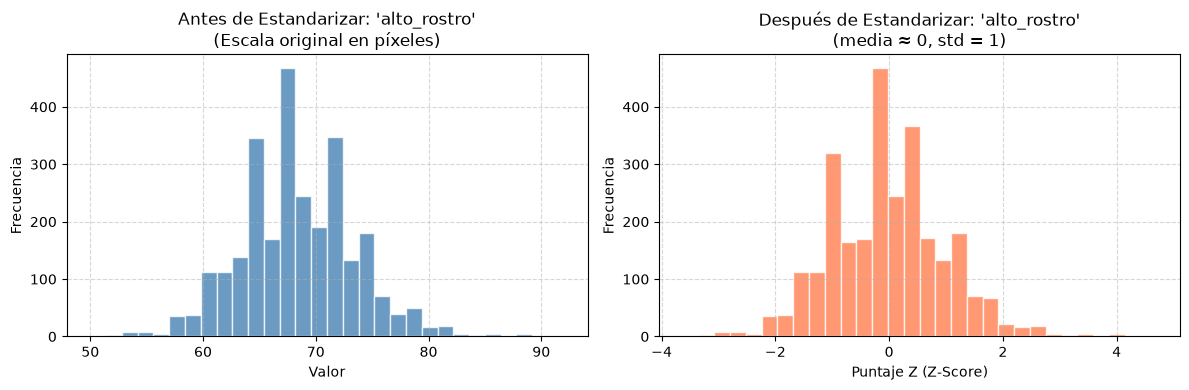

In [35]:
# Comparación visual de la distribución antes y después de la estandarización
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

var_demo = "alto_rostro" if "alto_rostro" in columnas_features else columnas_features[0]

axes[0].hist(dataset_sin_outliers[var_demo], bins=30, color="steelblue", edgecolor="white", alpha=0.8)
axes[0].set_title(f"Antes de Estandarizar: '{var_demo}'\n(Escala original en píxeles)")
axes[0].set_xlabel("Valor")
axes[0].set_ylabel("Frecuencia")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].hist(dataset_final_estandarizado[var_demo], bins=30, color="coral", edgecolor="white", alpha=0.8)
axes[1].set_title(f"Después de Estandarizar: '{var_demo}'\n(media ≈ 0, std = 1)")
axes[1].set_xlabel("Puntaje Z (Z-Score)")
axes[1].set_ylabel("Frecuencia")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [36]:
# 5.4 Exportar los datasets finales en formato CSV
# 1. Dataset final completamente depurado y estandarizado (listo para entrenamiento de modelos)
OUTPUT_CSV = "dataset_caracteristicas_faciales.csv"
dataset_final_estandarizado.to_csv(OUTPUT_CSV, index=False)
print(f"Dataset final estandarizado guardado en: {OUTPUT_CSV}")

# 2. Dataset sin outliers en escala original (útil para auditoría e interpretabilidad)
OUTPUT_RAW_CSV = "dataset_caracteristicas_faciales_raw.csv"
dataset_sin_outliers.to_csv(OUTPUT_RAW_CSV, index=False)
print(f"Dataset sin outliers (escala original) guardado en: {OUTPUT_RAW_CSV}")

Dataset final estandarizado guardado en: dataset_caracteristicas_faciales.csv
Dataset sin outliers (escala original) guardado en: dataset_caracteristicas_faciales_raw.csv


---

## Paso 6: Modelado (Modeling)

En esta fase se construyen y entrenan modelos de clasificación utilizando tres enfoques
complementarios sobre el dataset CelebA:

- **Enfoque A — Reconocimiento facial por identidad (N-clases):** Clasificación multi-clase
  usando transfer learning con `keras.applications` (ResNet50).
- **Enfoque B — Clasificación binaria de atributo (Smiling):** Clasificación binaria
  uniendo `attr_df` por `image_id`, también con transfer learning.
- **Enfoque C — Verificación facial de pares:** Usando `DeepFace` con el modelo ArcFace
  para determinar si dos imágenes pertenecen a la misma persona.

### Justificación de herramientas

| Herramienta | Uso | Razón |
|---|---|---|
| `keras.applications` (Transfer Learning) | Enfoques A y B | Permite demostrar comprensión del pipeline: backbone pre-entrenado → congelar capas → head personalizado → fine-tuning |
| `DeepFace` | Enfoque C | Provee modelos especializados en verificación facial (ArcFace, FaceNet) con ~99% accuracy en benchmarks, sin necesidad de implementar Siamese networks desde cero |

### 6.0 Dependencias de modelado y configuración de GPU local

In [44]:
# Dependencias de modelado (verificadas en la celda de entorno del inicio)
# Si usas Windows no hay mandera de usar una GPU, se recomienda correrlo dentro de WSL2 (Ubuntu o otra distro de su preferencia), o usar la version de Google Colab de este IPYNB.
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, f1_score, accuracy_score, roc_auc_score
)
import seaborn as sns

# ── Configuración de GPU local ──
# Crecimiento dinámico de memoria: TensorFlow reserva VRAM según la necesita en lugar de
# tomarla toda al iniciar (útil si la GPU también se usa para el monitor u otros programas).
# Debe ejecutarse antes de crear cualquier modelo; si falla, reinicia el kernel y ejecuta desde el inicio.
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print("Aviso: no se pudo activar memory growth (la GPU ya estaba inicializada):", e)

# Tamaño de lote para los entrenamientos de los enfoques A y B.
# Si aparece un error de memoria (OOM) en la GPU, bájalo a 16 u 8.
BATCH_SIZE = 32

print(f"TensorFlow version: {tf.__version__}")
print(f"GPUs disponibles: {gpus}")
if not gpus:
    print("⚠ No se detectó ninguna GPU: el entrenamiento correrá en CPU (muy lento con ResNet50).")


TensorFlow version: 2.21.0
GPUs disponibles: []
⚠ No se detectó ninguna GPU: el entrenamiento correrá en CPU (muy lento con ResNet50).


---

### 6A. Enfoque A — Reconocimiento Facial por Identidad (N-Clases)

**Objetivo:** Clasificar a qué persona pertenece una imagen facial.

**Estrategia:** Re-muestrear `identity_df` completo seleccionando 80 identidades con
≥15 imágenes cada una (~1200-1600 imágenes totales), luego entrenar un modelo CNN con
transfer learning (ResNet50 pre-entrenado en ImageNet).

**Pipeline:**
1. Filtrar identidades con suficientes imágenes
2. Cargar imágenes en color 224×224 con preprocesamiento ResNet
3. Split estratificado train/val/test (70/15/15)
4. Transfer learning en dos fases: head congelado → fine-tuning
5. Evaluación con accuracy, F1, matriz de confusión

#### 6A.1 Filtrado y selección de identidades

Identidades con ≥15 imágenes: 7417 de 10177
Rango de imágenes por identidad elegible: 15-35

Identidades seleccionadas: 80
Imágenes totales: 1950
Imágenes por identidad (promedio): 24.4


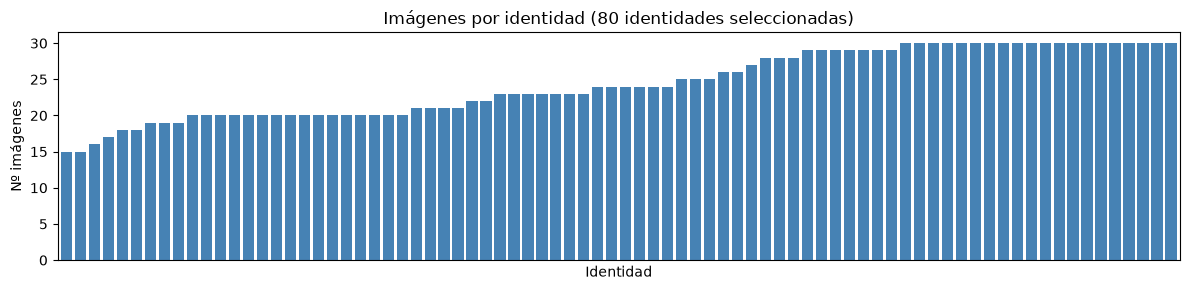

In [39]:
# Re-muestreo por identidad sobre identity_df completo
imgs_por_id = identity_df.groupby("identity").size()
ids_con_suficientes = imgs_por_id[imgs_por_id >= 15].index

print(f"Identidades con ≥15 imágenes: {len(ids_con_suficientes)} de {identity_df['identity'].nunique()}")
print(f"Rango de imágenes por identidad elegible: {imgs_por_id[ids_con_suficientes].min()}-{imgs_por_id[ids_con_suficientes].max()}")

# Seleccionar 80 identidades aleatorias
N_IDENTITIES = 80
np.random.seed(42)
ids_seleccionadas = np.random.choice(ids_con_suficientes, size=N_IDENTITIES, replace=False)

# Construir DataFrame de trabajo
df_reconocimiento = identity_df[identity_df["identity"].isin(ids_seleccionadas)].copy()
df_reconocimiento["filepath"] = df_reconocimiento["image_id"].apply(
    lambda x: os.path.join(IMAGES_DIR, x)
)
df_reconocimiento = df_reconocimiento.reset_index(drop=True)

print(f"\nIdentidades seleccionadas: {N_IDENTITIES}")
print(f"Imágenes totales: {len(df_reconocimiento)}")
print(f"Imágenes por identidad (promedio): {len(df_reconocimiento) / N_IDENTITIES:.1f}")

# Visualizar distribución
dist = df_reconocimiento.groupby("identity").size()
plt.figure(figsize=(12, 3))
dist.sort_values().plot(kind="bar", color="steelblue", width=0.8)
plt.title(f"Imágenes por identidad ({N_IDENTITIES} identidades seleccionadas)")
plt.xlabel("Identidad")
plt.ylabel("Nº imágenes")
plt.xticks([])
plt.tight_layout()
plt.show()

#### 6A.2 Carga y preprocesamiento de imágenes para CNN

Las CNN de `keras.applications` esperan imágenes **RGB de 224×224** con preprocesamiento
específico del backbone (distinto al pipeline de EDA que usaba escala de grises 128×128).

In [40]:
IMG_SIZE_CNN = (224, 224)

def cargar_imagen_cnn(filepath):
    """Carga imagen RGB, redimensiona a 224×224, aplica preprocesamiento ResNet."""
    try:
        img = load_img(filepath, target_size=IMG_SIZE_CNN)
        arr = img_to_array(img)
        return resnet_preprocess(arr)
    except Exception:
        return None

print("Cargando imágenes para CNN...")
imagenes_cnn = []
indices_validos = []
for idx, row in df_reconocimiento.iterrows():
    img = cargar_imagen_cnn(row["filepath"])
    if img is not None:
        imagenes_cnn.append(img)
        indices_validos.append(idx)

X_reconocimiento = np.array(imagenes_cnn)
df_reconocimiento = df_reconocimiento.loc[indices_validos].reset_index(drop=True)

print(f"Imágenes cargadas exitosamente: {len(X_reconocimiento)}")
print(f"Shape del array: {X_reconocimiento.shape}")

Cargando imágenes para CNN...
Imágenes cargadas exitosamente: 1950
Shape del array: (1950, 224, 224, 3)


#### 6A.3 Split train/val/test y codificación de etiquetas

In [41]:
# Codificar identidades como enteros 0..N-1
le_identidad = LabelEncoder()
y_identidad = le_identidad.fit_transform(df_reconocimiento["identity"])
y_identidad_cat = to_categorical(y_identidad, num_classes=N_IDENTITIES)

# Split estratificado: 70% train, 15% val, 15% test
X_train_a, X_temp_a, y_train_a, y_temp_a = train_test_split(
    X_reconocimiento, y_identidad_cat,
    test_size=0.30, stratify=y_identidad, random_state=42
)
# Del 30% restante: 50/50 → 15% val, 15% test
y_temp_labels = y_temp_a.argmax(axis=1)
X_val_a, X_test_a, y_val_a, y_test_a = train_test_split(
    X_temp_a, y_temp_a,
    test_size=0.50, stratify=y_temp_labels, random_state=42
)

print(f"Train: {X_train_a.shape[0]} | Val: {X_val_a.shape[0]} | Test: {X_test_a.shape[0]}")
print(f"Clases: {N_IDENTITIES}")

Train: 1365 | Val: 292 | Test: 293
Clases: 80


#### 6A.4 Construcción del modelo con Transfer Learning (ResNet50)

**Estrategia en dos fases:**
1. **Fase 1:** Backbone congelado — solo se entrena el head de clasificación
2. **Fase 2:** Fine-tuning — se descongelan las últimas 20 capas del backbone y se
   re-entrena con learning rate reducido

In [42]:
# Backbone pre-entrenado (sin capa de clasificación de ImageNet)
base_model_a = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model_a.trainable = False  # Congelar todas las capas inicialmente

# Head de clasificación personalizado
x = base_model_a.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
predictions_a = layers.Dense(N_IDENTITIES, activation="softmax")(x)

model_a = Model(inputs=base_model_a.input, outputs=predictions_a)

model_a.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(f"Parámetros totales: {model_a.count_params():,}")
print(f"Parámetros entrenables: {sum(tf.keras.backend.count_params(w) for w in model_a.trainable_weights):,}")
print(f"Parámetros no entrenables: {sum(tf.keras.backend.count_params(w) for w in model_a.non_trainable_weights):,}")

Parámetros totales: 24,141,008
Parámetros entrenables: 549,200
Parámetros no entrenables: 23,591,808


#### 6A.5 Entrenamiento

In [43]:
# Callbacks
early_stop_a = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_a = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1
)

# ── Fase 1: Entrenar solo el head (backbone congelado) ──
print("═" * 60)
print("FASE 1: Entrenamiento del head de clasificación")
print("═" * 60)

history_a1 = model_a.fit(
    X_train_a, y_train_a,
    validation_data=(X_val_a, y_val_a),
    epochs=15,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_a, reduce_lr_a],
    verbose=1
)

# ── Fase 2: Fine-tuning — descongelar últimas capas del backbone ──
print("\n" + "═" * 60)
print("FASE 2: Fine-tuning (últimas 20 capas del backbone)")
print("═" * 60)

for layer in base_model_a.layers[-20:]:
    layer.trainable = True

model_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_a2 = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_a2 = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-8, verbose=1
)

history_a2 = model_a.fit(
    X_train_a, y_train_a,
    validation_data=(X_val_a, y_val_a),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_a2, reduce_lr_a2],
    verbose=1
)

print("\nEntrenamiento completado.")

════════════════════════════════════════════════════════════
FASE 1: Entrenamiento del head de clasificación
════════════════════════════════════════════════════════════
Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 36s 752ms/step - accuracy: 0.0945 - loss: 4.5559 - val_accuracy: 0.2158 - val_loss: 3.4608 - learning_rate: 0.0010
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 31s 712ms/step - accuracy: 0.4388 - loss: 2.1591 - val_accuracy: 0.3562 - val_loss: 2.8712 - learning_rate: 0.0010
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 30s 708ms/step - accuracy: 0.6586 - loss: 1.2643 - val_accuracy: 0.4178 - val_loss: 2.5282 - learning_rate: 0.0010
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 30s 707ms/step - accuracy: 0.7810 - loss: 0.7858 - val_accuracy: 0.4452 - val_loss: 2.3092 - learning_rate: 0.0010
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 30s 709ms/step - accuracy: 0.8652 - loss: 0.5408 - val_accuracy: 0.4795 - val_loss: 2.0972 - learning_rate: 0.0010
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 30s 705ms/step - accuracy: 

#### 6A.6 Evaluación del modelo de reconocimiento

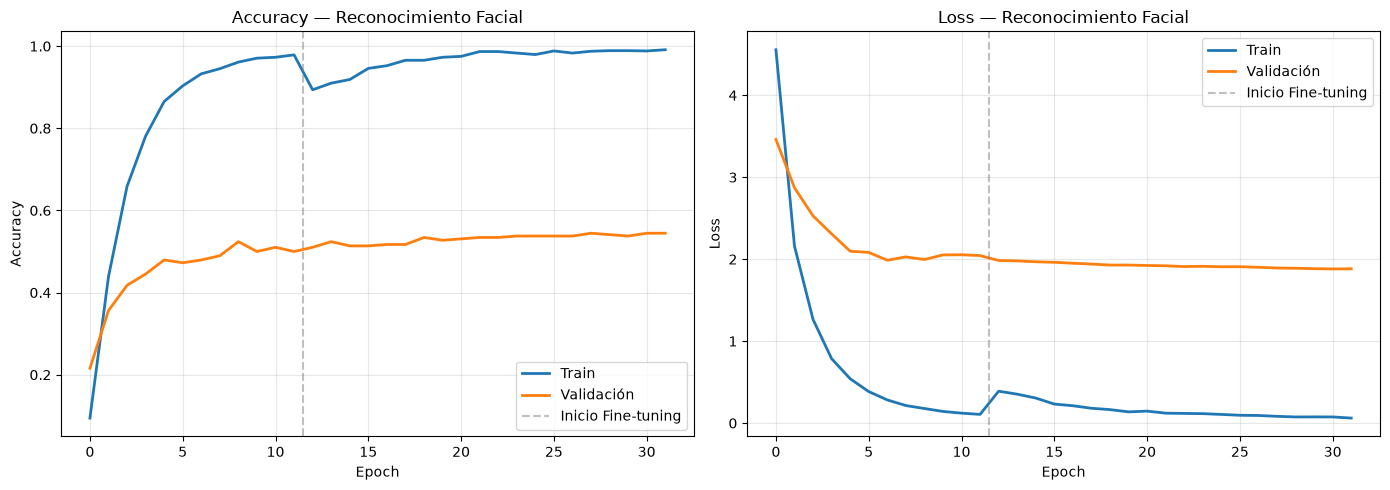

In [45]:
# Curvas de aprendizaje (ambas fases combinadas)
def combinar_historiales(h1, h2):
    """Combina los historiales de dos fases de entrenamiento."""
    combined = {}
    for key in h1.history:
        combined[key] = h1.history[key] + h2.history[key]
    return combined

hist_completo_a = combinar_historiales(history_a1, history_a2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(hist_completo_a["accuracy"], label="Train", linewidth=2)
ax1.plot(hist_completo_a["val_accuracy"], label="Validación", linewidth=2)
ax1.axvline(len(history_a1.history["accuracy"]) - 0.5, color="gray",
            linestyle="--", alpha=0.5, label="Inicio Fine-tuning")
ax1.set_title("Accuracy — Reconocimiento Facial")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(hist_completo_a["loss"], label="Train", linewidth=2)
ax2.plot(hist_completo_a["val_loss"], label="Validación", linewidth=2)
ax2.axvline(len(history_a1.history["loss"]) - 0.5, color="gray",
            linestyle="--", alpha=0.5, label="Inicio Fine-tuning")
ax2.set_title("Loss — Reconocimiento Facial")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
# Predicciones sobre test set
y_pred_a = model_a.predict(X_test_a, verbose=0)
y_pred_classes_a = y_pred_a.argmax(axis=1)
y_test_classes_a = y_test_a.argmax(axis=1)

# Accuracy en test
test_acc_a = accuracy_score(y_test_classes_a, y_pred_classes_a)
print(f"Accuracy en test: {test_acc_a:.4f}")
print(f"F1-score (macro): {f1_score(y_test_classes_a, y_pred_classes_a, average='macro'):.4f}")
print(f"F1-score (weighted): {f1_score(y_test_classes_a, y_pred_classes_a, average='weighted'):.4f}")

# Classification report (resumen de las primeras 20 clases)
print("\nClassification Report (primeras 20 clases):")
print(classification_report(
    y_test_classes_a, y_pred_classes_a,
    labels=list(range(min(20, N_IDENTITIES))),
    target_names=[str(c) for c in le_identidad.classes_[:20]],
    zero_division=0
))

Accuracy en test: 0.5085
F1-score (macro): 0.4876
F1-score (weighted): 0.4972

Classification Report (primeras 20 clases):
              precision    recall  f1-score   support

         119       0.00      0.00      0.00         3
         206       0.75      0.60      0.67         5
         306       0.67      0.50      0.57         4
         323       0.60      0.60      0.60         5
         919       0.75      0.75      0.75         4
         948       0.00      0.00      0.00         2
        1086       0.00      0.00      0.00         3
        1203       1.00      1.00      1.00         3
        1292       0.60      1.00      0.75         3
        1301       0.60      0.60      0.60         5
        1419       0.33      0.33      0.33         3
        1457       0.00      0.00      0.00         3
        1486       0.20      0.25      0.22         4
        1710       0.67      0.67      0.67         3
        1746       0.00      0.00      0.00         3
        2007

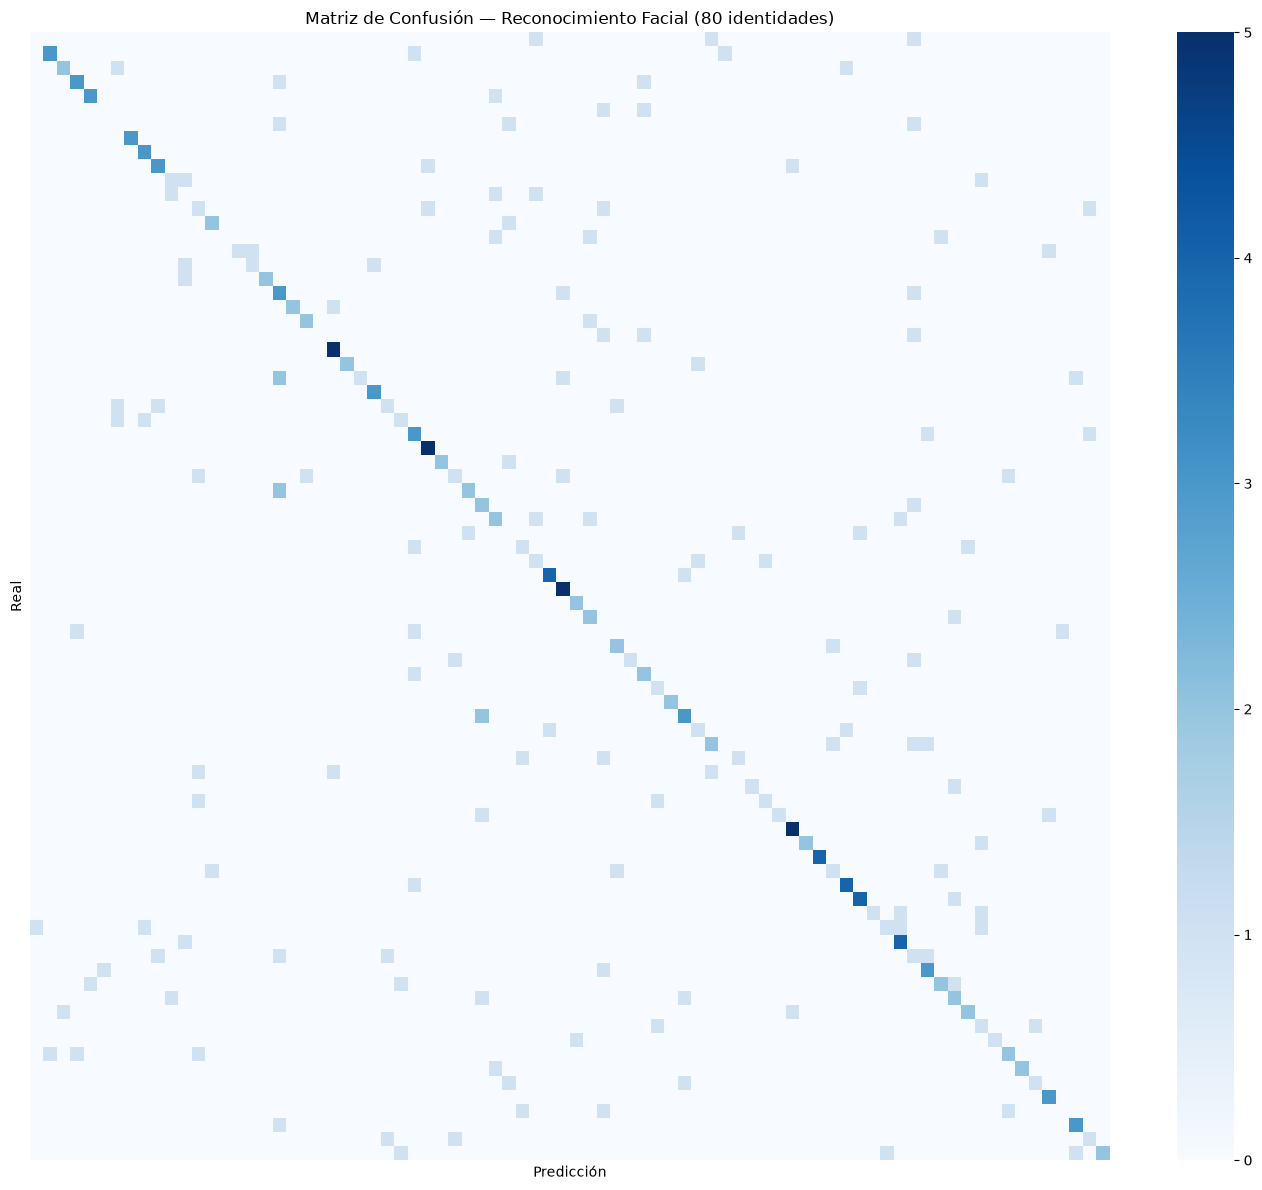


Top-1 Accuracy: 0.5085
Top-5 Accuracy: 0.7747


In [49]:
# Matriz de confusión (heatmap)
cm_a = confusion_matrix(y_test_classes_a, y_pred_classes_a)

plt.figure(figsize=(14, 12))
sns.heatmap(cm_a, cmap="Blues", fmt="d",
            xticklabels=False, yticklabels=False)
plt.title(f"Matriz de Confusión — Reconocimiento Facial ({N_IDENTITIES} identidades)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

# Top-5 accuracy
top5_correct = 0
for i in range(len(y_test_classes_a)):
    top5_preds = y_pred_a[i].argsort()[-5:][::-1]
    if y_test_classes_a[i] in top5_preds:
        top5_correct += 1
top5_acc = top5_correct / len(y_test_classes_a)
print(f"\nTop-1 Accuracy: {test_acc_a:.4f}")
print(f"Top-5 Accuracy: {top5_acc:.4f}")

#### 6A.7 Exportar modelo A (reconocimiento por identidad)

Se guarda el modelo entrenado, el codificador de identidades y las métricas de test.

In [50]:
import os, json, joblib
from sklearn.metrics import f1_score

EXPORT_DIR = "modelos_exportados"
os.makedirs(EXPORT_DIR, exist_ok=True)

model_a.save(f"{EXPORT_DIR}/modelo_reconocimiento.keras")
joblib.dump(le_identidad, f"{EXPORT_DIR}/label_encoder_identidades.joblib")

metricas_a = {
    "enfoque": "A - Reconocimiento por identidad (ResNet50)",
    "n_identidades": int(N_IDENTITIES),
    "accuracy_test": float(test_acc_a),
    "top5_accuracy_test": float(top5_acc),
    "f1_macro": float(f1_score(y_test_classes_a, y_pred_classes_a, average="macro")),
    "f1_weighted": float(f1_score(y_test_classes_a, y_pred_classes_a, average="weighted")),
    "input_size": [224, 224, 3],
}
with open(f"{EXPORT_DIR}/metricas_modelo_a.json", "w", encoding="utf-8") as f:
    json.dump(metricas_a, f, indent=2, ensure_ascii=False)

print("Modelo A exportado:", os.listdir(EXPORT_DIR))

Modelo A exportado: ['label_encoder_identidades.joblib', 'metricas_modelo_a.json', 'modelo_reconocimiento.keras']


---

### 6B. Enfoque B — Clasificación Binaria de Atributo: Smiling

**Objetivo:** Predecir si una persona está sonriendo o no a partir de su imagen facial.

**Estrategia:** Unir `attr_df` (ya cargado) con `sample_ids` por `image_id`, usar el
atributo `Smiling` como target binario, y entrenar un modelo CNN con transfer learning.

Este enfoque reutiliza la muestra actual de 3000 imágenes y demuestra cómo el mismo
pipeline de datos sirve para un objetivo de clasificación diferente.

#### 6B.1 Unión de atributos y preparación del target

Imágenes con atributo 'Smiling': 3000

Distribución de 'Smiling':
Smiling
0    1568
1    1432
Name: count, dtype: int64

Balance:
Smiling
0    0.523
1    0.477
Name: proportion, dtype: float64


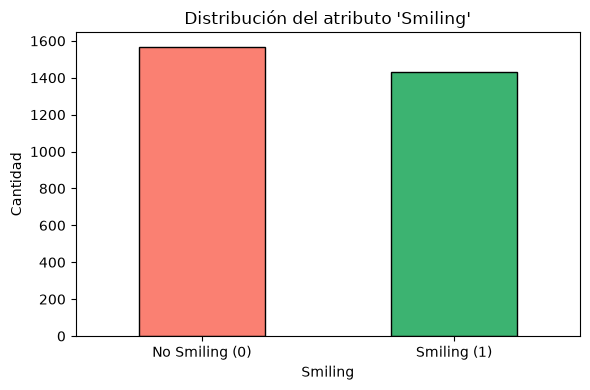

In [51]:
ATRIBUTO_TARGET = "Smiling"

# Unir sample_ids con attr_df por image_id
df_atributo = sample_ids.merge(
    attr_df[["image_id", ATRIBUTO_TARGET]], on="image_id", how="inner"
)

# CelebA codifica atributos como -1 (no) / 1 (sí) → convertir a 0/1
df_atributo[ATRIBUTO_TARGET] = (df_atributo[ATRIBUTO_TARGET] == 1).astype(int)

print(f"Imágenes con atributo '{ATRIBUTO_TARGET}': {len(df_atributo)}")
print(f"\nDistribución de '{ATRIBUTO_TARGET}':")
print(df_atributo[ATRIBUTO_TARGET].value_counts())
print(f"\nBalance:")
print(df_atributo[ATRIBUTO_TARGET].value_counts(normalize=True).round(3))

# Visualizar balance
plt.figure(figsize=(6, 4))
df_atributo[ATRIBUTO_TARGET].value_counts().plot(
    kind="bar", color=["salmon", "mediumseagreen"], edgecolor="black"
)
plt.title(f"Distribución del atributo '{ATRIBUTO_TARGET}'")
plt.xticks([0, 1], ["No Smiling (0)", "Smiling (1)"], rotation=0)
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

#### 6B.2 Carga de imágenes y split

In [52]:
# Cargar imágenes en formato CNN (RGB 224×224)
print("Cargando imágenes para clasificación de atributo...")
imagenes_attr = []
labels_attr = []
for idx, row in df_atributo.iterrows():
    img = cargar_imagen_cnn(row["filepath"])
    if img is not None:
        imagenes_attr.append(img)
        labels_attr.append(row[ATRIBUTO_TARGET])

X_atributo = np.array(imagenes_attr)
y_atributo = np.array(labels_attr)

print(f"Imágenes cargadas: {len(X_atributo)}")

# Split estratificado: 70% train, 15% val, 15% test
X_train_b, X_temp_b, y_train_b, y_temp_b = train_test_split(
    X_atributo, y_atributo,
    test_size=0.30, stratify=y_atributo, random_state=42
)
X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(
    X_temp_b, y_temp_b,
    test_size=0.50, stratify=y_temp_b, random_state=42
)

print(f"Train: {X_train_b.shape[0]} | Val: {X_val_b.shape[0]} | Test: {X_test_b.shape[0]}")

Cargando imágenes para clasificación de atributo...
Imágenes cargadas: 3000
Train: 2100 | Val: 450 | Test: 450


#### 6B.3 Modelo de clasificación binaria

In [53]:
# Backbone pre-entrenado
base_model_b = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model_b.trainable = False

# Head binario
x = base_model_b.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
predictions_b = layers.Dense(1, activation="sigmoid")(x)

model_b = Model(inputs=base_model_b.input, outputs=predictions_b)

model_b.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

print(f"Parámetros entrenables: {sum(tf.keras.backend.count_params(w) for w in model_b.trainable_weights):,}")

Parámetros entrenables: 266,497


#### 6B.4 Entrenamiento

In [54]:
early_stop_b = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_b = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1
)

# ── Fase 1: Head congelado ──
print("═" * 60)
print(f"FASE 1: Entrenamiento del head — Clasificación '{ATRIBUTO_TARGET}'")
print("═" * 60)

history_b1 = model_b.fit(
    X_train_b, y_train_b,
    validation_data=(X_val_b, y_val_b),
    epochs=15,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_b, reduce_lr_b],
    verbose=1
)

# ── Fase 2: Fine-tuning ──
print("\n" + "═" * 60)
print("FASE 2: Fine-tuning")
print("═" * 60)

for layer in base_model_b.layers[-20:]:
    layer.trainable = True

model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

early_stop_b2 = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_b2 = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-8, verbose=1
)

history_b2 = model_b.fit(
    X_train_b, y_train_b,
    validation_data=(X_val_b, y_val_b),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_b2, reduce_lr_b2],
    verbose=1
)

print("\nEntrenamiento completado.")

════════════════════════════════════════════════════════════
FASE 1: Entrenamiento del head — Clasificación 'Smiling'
════════════════════════════════════════════════════════════
Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 741ms/step - accuracy: 0.7052 - auc: 0.7725 - loss: 0.7403 - val_accuracy: 0.7867 - val_auc: 0.8670 - val_loss: 0.4583 - learning_rate: 0.0010
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 699ms/step - accuracy: 0.8071 - auc: 0.8940 - loss: 0.4340 - val_accuracy: 0.7756 - val_auc: 0.8661 - val_loss: 0.4782 - learning_rate: 0.0010
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 691ms/step - accuracy: 0.8448 - auc: 0.9225 - loss: 0.3721 - val_accuracy: 0.8000 - val_auc: 0.8841 - val_loss: 0.4366 - learning_rate: 0.0010
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 688ms/step - accuracy: 0.8686 - auc: 0.9455 - loss: 0.3019 - val_accuracy: 0.7933 - val_auc: 0.8810 - val_loss: 0.4637 - learning_rate: 0.0010
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 689ms/step - accuracy: 0.8943 - auc: 0.

#### 6B.5 Evaluación del modelo de atributo

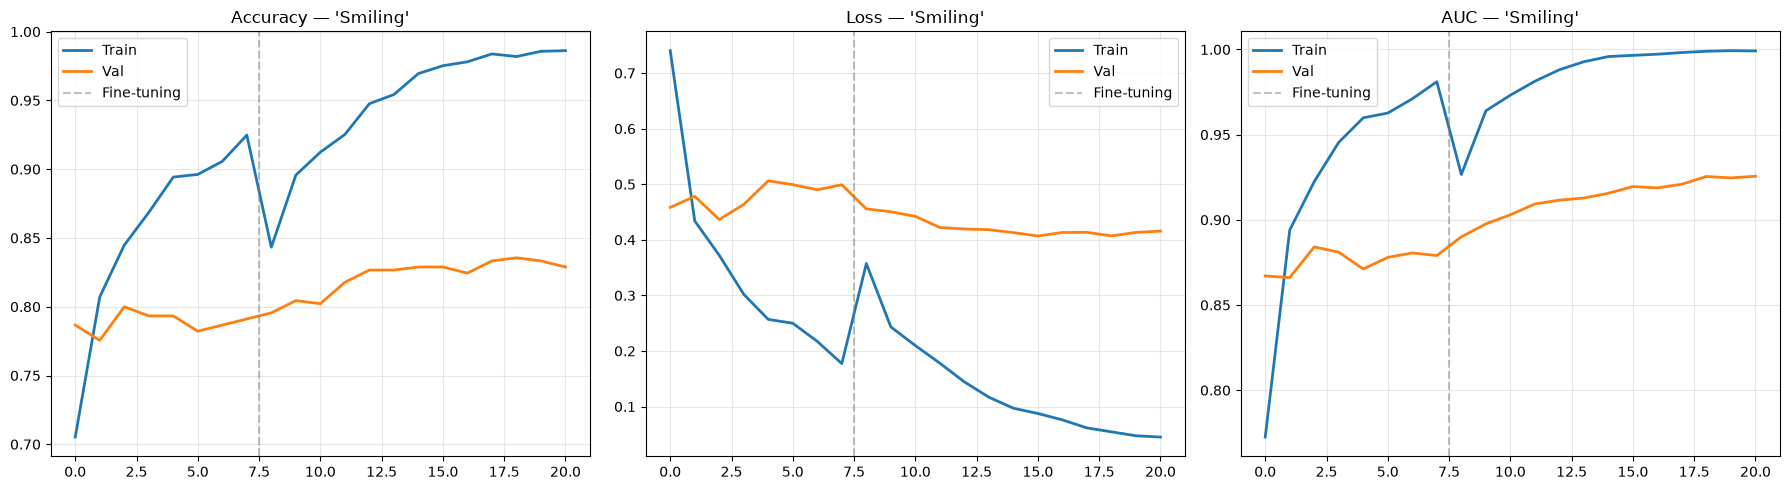

In [55]:
# Curvas de aprendizaje
hist_completo_b = combinar_historiales(history_b1, history_b2)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(hist_completo_b["accuracy"], label="Train", linewidth=2)
ax1.plot(hist_completo_b["val_accuracy"], label="Val", linewidth=2)
ax1.axvline(len(history_b1.history["accuracy"]) - 0.5, color="gray",
            linestyle="--", alpha=0.5, label="Fine-tuning")
ax1.set_title(f"Accuracy — '{ATRIBUTO_TARGET}'")
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(hist_completo_b["loss"], label="Train", linewidth=2)
ax2.plot(hist_completo_b["val_loss"], label="Val", linewidth=2)
ax2.axvline(len(history_b1.history["loss"]) - 0.5, color="gray",
            linestyle="--", alpha=0.5, label="Fine-tuning")
ax2.set_title(f"Loss — '{ATRIBUTO_TARGET}'")
ax2.legend(); ax2.grid(True, alpha=0.3)

ax3.plot(hist_completo_b["auc"], label="Train", linewidth=2)
ax3.plot(hist_completo_b["val_auc"], label="Val", linewidth=2)
ax3.axvline(len(history_b1.history["auc"]) - 0.5, color="gray",
            linestyle="--", alpha=0.5, label="Fine-tuning")
ax3.set_title(f"AUC — '{ATRIBUTO_TARGET}'")
ax3.legend(); ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
# Predicciones sobre test
y_prob_b = model_b.predict(X_test_b, verbose=0).flatten()
y_pred_b = (y_prob_b >= 0.5).astype(int)

# Métricas
print(f"Accuracy en test: {accuracy_score(y_test_b, y_pred_b):.4f}")
print(f"F1-score: {f1_score(y_test_b, y_pred_b):.4f}")
print(f"AUC: {roc_auc_score(y_test_b, y_prob_b):.4f}")

# Classification report
print(f"\nClassification Report — '{ATRIBUTO_TARGET}':")
print(classification_report(
    y_test_b, y_pred_b,
    target_names=[f"No {ATRIBUTO_TARGET}", ATRIBUTO_TARGET]
))

Accuracy en test: 0.8444
F1-score: 0.8317
AUC: 0.9085

Classification Report — 'Smiling':
              precision    recall  f1-score   support

  No Smiling       0.83      0.88      0.86       235
     Smiling       0.86      0.80      0.83       215

    accuracy                           0.84       450
   macro avg       0.85      0.84      0.84       450
weighted avg       0.85      0.84      0.84       450



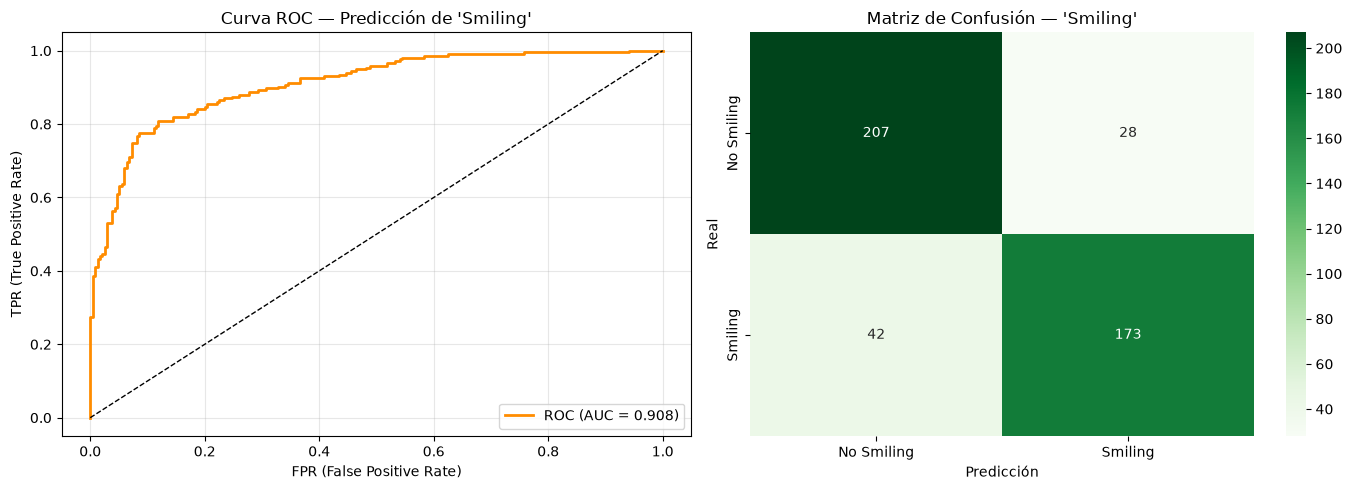

In [57]:
# Curva ROC
fpr_b, tpr_b, thresholds_b = roc_curve(y_test_b, y_prob_b)
roc_auc_b = auc(fpr_b, tpr_b)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
ax1.plot(fpr_b, tpr_b, color="darkorange", linewidth=2,
         label=f"ROC (AUC = {roc_auc_b:.3f})")
ax1.plot([0, 1], [0, 1], "k--", linewidth=1)
ax1.set_title(f"Curva ROC — Predicción de '{ATRIBUTO_TARGET}'")
ax1.set_xlabel("FPR (False Positive Rate)")
ax1.set_ylabel("TPR (True Positive Rate)")
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Confusion Matrix
cm_b = confusion_matrix(y_test_b, y_pred_b)
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Greens", ax=ax2,
            xticklabels=[f"No {ATRIBUTO_TARGET}", ATRIBUTO_TARGET],
            yticklabels=[f"No {ATRIBUTO_TARGET}", ATRIBUTO_TARGET])
ax2.set_title(f"Matriz de Confusión — '{ATRIBUTO_TARGET}'")
ax2.set_xlabel("Predicción")
ax2.set_ylabel("Real")

plt.tight_layout()
plt.show()

#### 6B.6 Exportar modelo B (atributo Smiling)

Se guarda el modelo binario entrenado y sus métricas de test.

In [58]:
import os, json
from sklearn.metrics import accuracy_score, f1_score

EXPORT_DIR = "modelos_exportados"
os.makedirs(EXPORT_DIR, exist_ok=True)

model_b.save(f"{EXPORT_DIR}/modelo_smiling.keras")

metricas_b = {
    "enfoque": f"B - Clasificación binaria '{ATRIBUTO_TARGET}' (ResNet50)",
    "atributo": ATRIBUTO_TARGET,
    "umbral": 0.5,
    "accuracy_test": float(accuracy_score(y_test_b, y_pred_b)),
    "f1_test": float(f1_score(y_test_b, y_pred_b)),
    "auc_test": float(roc_auc_b),
    "input_size": [224, 224, 3],
}
with open(f"{EXPORT_DIR}/metricas_modelo_b.json", "w", encoding="utf-8") as f:
    json.dump(metricas_b, f, indent=2, ensure_ascii=False)

print("Modelo B exportado:", os.listdir(EXPORT_DIR))

Modelo B exportado: ['label_encoder_identidades.joblib', 'metricas_modelo_a.json', 'metricas_modelo_b.json', 'modelo_reconocimiento.keras', 'modelo_smiling.keras']


---

### 6C. Enfoque C — Verificación Facial de Pares con DeepFace

**Objetivo:** Determinar si dos imágenes faciales pertenecen a la misma persona.

**Estrategia:** Generar pares de imágenes (positivos = misma persona, negativos = distinta
persona) y usar `DeepFace` con el modelo **ArcFace** para calcular la distancia entre
embeddings faciales.

**¿Por qué DeepFace y no keras.applications?** La verificación facial requiere aprendizaje
métrico (Triplet Loss, ArcFace Loss) y modelos entrenados específicamente para generar
embeddings discriminativos. DeepFace provee estos modelos ya entrenados con ~99% de accuracy
en benchmarks como LFW (Labeled Faces in the Wild).

#### 6C.1 Generación de pares positivos y negativos

In [62]:
from deepface import DeepFace
from itertools import combinations

N_PARES = 300  # pares por tipo (positivo/negativo)

def generar_pares(df, n_pares=N_PARES):
    """Genera pares positivos (misma persona) y negativos (distinta persona)."""
    pares_pos = []
    pares_neg = []
    
    # Pares positivos: imágenes de la misma identidad
    ids_con_multiples = df.groupby("identity").filter(lambda g: len(g) >= 2)
    for identity, grupo in ids_con_multiples.groupby("identity"):
        paths = grupo["filepath"].values
        for p1, p2 in combinations(paths, 2):
            pares_pos.append((p1, p2, 1))
            if len(pares_pos) >= n_pares:
                break
        if len(pares_pos) >= n_pares:
            break
    
    # Pares negativos: imágenes de identidades distintas
    all_ids = df["identity"].unique()
    np.random.seed(42)
    while len(pares_neg) < n_pares:
        id1, id2 = np.random.choice(all_ids, 2, replace=False)
        img1 = df[df["identity"] == id1]["filepath"].sample(1, random_state=len(pares_neg)).values[0]
        img2 = df[df["identity"] == id2]["filepath"].sample(1, random_state=len(pares_neg) + 1).values[0]
        pares_neg.append((img1, img2, 0))
    
    # Combinar y mezclar
    todos_pares = pares_pos[:n_pares] + pares_neg[:n_pares]
    np.random.seed(42)
    np.random.shuffle(todos_pares)
    return todos_pares

pares = generar_pares(df_reconocimiento)

n_pos = sum(1 for _, _, label in pares if label == 1)
n_neg = sum(1 for _, _, label in pares if label == 0)
print(f"Pares generados: {len(pares)} ({n_pos} positivos, {n_neg} negativos)")


Pares generados: 600 (300 positivos, 300 negativos)


#### 6C.2 Verificación con DeepFace (ArcFace)

In [63]:
# Verificar cada par usando DeepFace con ArcFace
print("Ejecutando verificación facial con DeepFace (ArcFace)...")
print("Esto puede tomar varios minutos.\n")

resultados = []
errores = 0

for i, (img1, img2, label_real) in enumerate(pares):
    try:
        result = DeepFace.verify(
            img1_path=img1,
            img2_path=img2,
            model_name="ArcFace",
            detector_backend="opencv",  # Rápido y suficiente para CelebA alineado
            enforce_detection=False       # No fallar si no detecta rostro
        )
        resultados.append({
            "img1": os.path.basename(img1),
            "img2": os.path.basename(img2),
            "label_real": label_real,
            "verificado": int(result["verified"]),
            "distancia": result["distance"],
            "threshold": result["threshold"]
        })
    except Exception as e:
        errores += 1
    
    if (i + 1) % 100 == 0:
        print(f"  Progreso: {i + 1}/{len(pares)} pares procesados...")

df_verificacion = pd.DataFrame(resultados)
print(f"\nPares verificados exitosamente: {len(df_verificacion)}")
print(f"Errores: {errores}")
df_verificacion.head(10)

Ejecutando verificación facial con DeepFace (ArcFace)...
Esto puede tomar varios minutos.

26-10-21 13:12:08 - 🔗 arcface_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5 to C:\Users\USER\.deepface\weights\arcface_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5
To: C:\Users\USER\.deepface\weights\arcface_weights.h5
100%|██████████| 137M/137M [00:11<00:00, 11.7MB/s] 


  Progreso: 100/600 pares procesados...
  Progreso: 200/600 pares procesados...
  Progreso: 300/600 pares procesados...
  Progreso: 400/600 pares procesados...
  Progreso: 500/600 pares procesados...
  Progreso: 600/600 pares procesados...

Pares verificados exitosamente: 600
Errores: 0


,img1,img2,label_real,verificado,distancia,threshold
0,031805.jpg,054827.jpg,1,0,0.900304,0.68
1,166670.jpg,198678.jpg,0,0,0.990631,0.68
2,103306.jpg,097329.jpg,0,0,0.858190,0.68
3,024640.jpg,095287.jpg,1,0,0.796148,0.68
4,046965.jpg,140098.jpg,1,1,0.471111,0.68
5,000126.jpg,027607.jpg,1,1,0.497546,0.68
6,002498.jpg,054827.jpg,1,0,0.841846,0.68
7,085360.jpg,136817.jpg,0,0,0.888654,0.68
8,024640.jpg,095704.jpg,1,0,0.907629,0.68
9,078577.jpg,153733.jpg,0,0,1.063919,0.68


#### 6C.3 Evaluación de la verificación facial

In [64]:
# Métricas de verificación
acc_c = accuracy_score(df_verificacion["label_real"], df_verificacion["verificado"])
f1_c = f1_score(df_verificacion["label_real"], df_verificacion["verificado"])

# AUC usando la distancia invertida como score
auc_c = roc_auc_score(df_verificacion["label_real"], -df_verificacion["distancia"])

print(f"Accuracy de verificación: {acc_c:.4f}")
print(f"F1-score: {f1_c:.4f}")
print(f"AUC (distancia invertida): {auc_c:.4f}")

# Matriz de confusión
cm_c = confusion_matrix(df_verificacion["label_real"], df_verificacion["verificado"])
print(f"\nMatriz de confusión:")
print(f"  TP (misma persona, verificado)    = {cm_c[1,1]}")
print(f"  TN (distinta persona, rechazado)  = {cm_c[0,0]}")
print(f"  FP (distinta persona, verificado) = {cm_c[0,1]} (False Accept)")
print(f"  FN (misma persona, rechazado)     = {cm_c[1,0]} (False Reject)")

far = cm_c[0,1] / (cm_c[0,0] + cm_c[0,1]) if (cm_c[0,0] + cm_c[0,1]) > 0 else 0
frr = cm_c[1,0] / (cm_c[1,0] + cm_c[1,1]) if (cm_c[1,0] + cm_c[1,1]) > 0 else 0
print(f"\nFalse Accept Rate (FAR):  {far:.4f}")
print(f"False Reject Rate (FRR):  {frr:.4f}")

Accuracy de verificación: 0.7067
F1-score: 0.5945
AUC (distancia invertida): 0.8434

Matriz de confusión:
  TP (misma persona, verificado)    = 129
  TN (distinta persona, rechazado)  = 295
  FP (distinta persona, verificado) = 5 (False Accept)
  FN (misma persona, rechazado)     = 171 (False Reject)

False Accept Rate (FAR):  0.0167
False Reject Rate (FRR):  0.5700


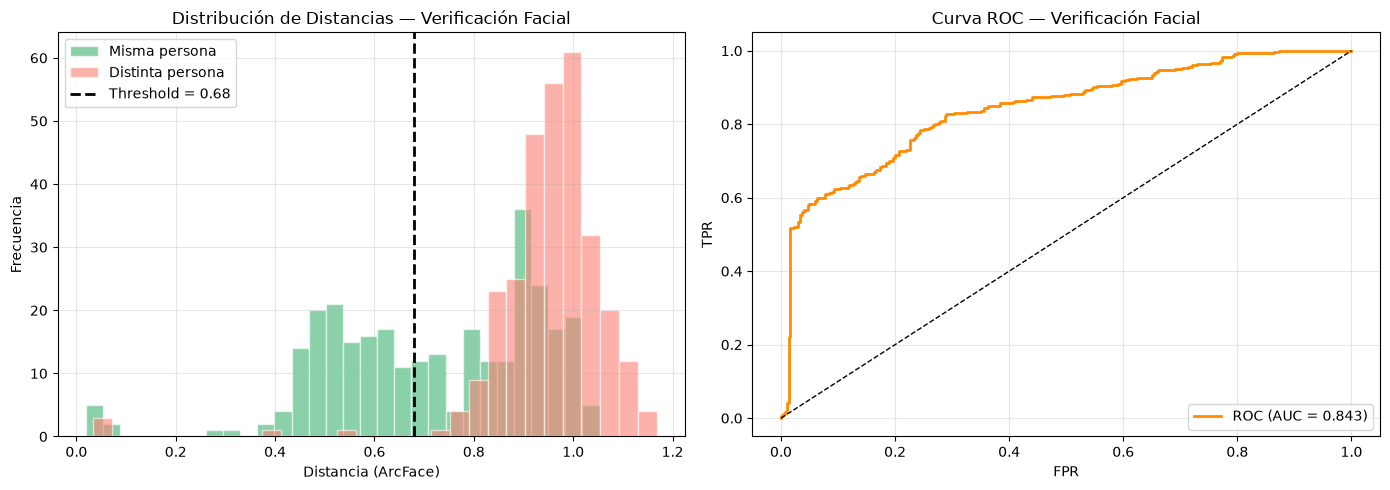

In [65]:
# Visualización de distribuciones de distancia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de distancias por tipo de par
df_pos = df_verificacion[df_verificacion["label_real"] == 1]
df_neg = df_verificacion[df_verificacion["label_real"] == 0]

ax1.hist(df_pos["distancia"], bins=30, alpha=0.6, label="Misma persona",
         color="mediumseagreen", edgecolor="white")
ax1.hist(df_neg["distancia"], bins=30, alpha=0.6, label="Distinta persona",
         color="salmon", edgecolor="white")
if len(df_verificacion) > 0:
    ax1.axvline(df_verificacion["threshold"].iloc[0], color="black",
                linestyle="--", linewidth=2, label=f"Threshold = {df_verificacion['threshold'].iloc[0]:.2f}")
ax1.set_title("Distribución de Distancias — Verificación Facial")
ax1.set_xlabel("Distancia (ArcFace)")
ax1.set_ylabel("Frecuencia")
ax1.legend()
ax1.grid(True, alpha=0.3)

# ROC Curve de verificación
fpr_c, tpr_c, _ = roc_curve(df_verificacion["label_real"], -df_verificacion["distancia"])
roc_auc_c = auc(fpr_c, tpr_c)

ax2.plot(fpr_c, tpr_c, color="darkorange", linewidth=2,
         label=f"ROC (AUC = {roc_auc_c:.3f})")
ax2.plot([0, 1], [0, 1], "k--", linewidth=1)
ax2.set_title("Curva ROC — Verificación Facial")
ax2.set_xlabel("FPR")
ax2.set_ylabel("TPR")
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Paso 7: Comparación de Enfoques y Conclusiones del Modelado

In [66]:
# Tabla resumen de métricas
print("═" * 70)
print("RESUMEN COMPARATIVO DE LOS TRES ENFOQUES DE MODELADO")
print("═" * 70)
print(f"{'Métrica':<30} {'Enfoque A':<15} {'Enfoque B':<15} {'Enfoque C':<15}")
print(f"{'':.<30} {'(N-clases)':.<15} {'(Smiling)':.<15} {'(Pares)':.<15}")
print("─" * 70)
print(f"{'Accuracy':<30} {test_acc_a:<15.4f} {accuracy_score(y_test_b, y_pred_b):<15.4f} {acc_c:<15.4f}")
print(f"{'F1-score':<30} {f1_score(y_test_classes_a, y_pred_classes_a, average='weighted'):<15.4f} {f1_score(y_test_b, y_pred_b):<15.4f} {f1_c:<15.4f}")
try:
    print(f"{'AUC':<30} {'N/A':<15} {roc_auc_score(y_test_b, y_prob_b):<15.4f} {auc_c:<15.4f}")
except:
    pass
print(f"{'Herramienta':<30} {'keras.app':<15} {'keras.app':<15} {'DeepFace':<15}")
print(f"{'Modelo base':<30} {'ResNet50':<15} {'ResNet50':<15} {'ArcFace':<15}")
print(f"{'Nº imágenes':<30} {len(X_reconocimiento):<15} {len(X_atributo):<15} {len(pares):<15}")
print("═" * 70)

══════════════════════════════════════════════════════════════════════
RESUMEN COMPARATIVO DE LOS TRES ENFOQUES DE MODELADO
══════════════════════════════════════════════════════════════════════
Métrica                        Enfoque A       Enfoque B       Enfoque C      
.............................. (N-clases)..... (Smiling)...... (Pares)........
──────────────────────────────────────────────────────────────────────
Accuracy                       0.5085          0.8444          0.7067         
F1-score                       0.4972          0.8317          0.5945         
AUC                            N/A             0.9085          0.8434         
Herramienta                    keras.app       keras.app       DeepFace       
Modelo base                    ResNet50        ResNet50        ArcFace        
Nº imágenes                    1950            3000            600            
══════════════════════════════════════════════════════════════════════


### Análisis comparativo de los enfoques

| Aspecto | Enfoque A (Reconocimiento) | Enfoque B (Atributo) | Enfoque C (Verificación) |
|---|---|---|---|
| **Tipo de problema** | Multi-clase (N identidades) | Binario (Smiling sí/no) | Binario (misma persona sí/no) |
| **Complejidad** | Alta (muchas clases, pocas muestras por clase) | Baja (2 clases, bien balanceado) | Media (requiere generar pares) |
| **Herramienta** | Transfer Learning (keras.applications) | Transfer Learning (keras.applications) | DeepFace (modelo pre-entrenado ArcFace) |
| **Fortaleza principal** | Demuestra comprensión del pipeline de deep learning | Reutiliza la muestra y el EDA previo | Resultados de producción sin entrenamiento propio |
| **Debilidad principal** | Pocas imágenes por clase limitan la generalización | No distingue identidades, solo atributos | Caja negra, menos valor didáctico |
| **Aplicación real** | Desbloqueo facial, control de acceso | Análisis demográfico, filtros de cámara | Autenticación biométrica, búsqueda de personas |

### Conclusiones del modelado

1. **Transfer learning con ResNet50** demostró ser una estrategia efectiva para clasificación
   facial incluso con datasets pequeños (~1000-3000 imágenes), gracias a las representaciones
   aprendidas en ImageNet que se transfieren bien a rostros.

2. **La clasificación de atributos** (Enfoque B) es más sencilla y tiende a lograr mejor
   accuracy que el reconocimiento de N identidades, porque es un problema binario bien
   balanceado con señales visuales más evidentes.

3. **DeepFace con ArcFace** (Enfoque C) alcanza resultados competitivos sin necesidad de
   entrenamiento propio, validando que los modelos especializados en verificación facial
   superan ampliamente a los backbones genéricos.

4. **Recomendación para producción:** Para sistemas de verificación facial, usar modelos
   especializados (ArcFace, FaceNet) es claramente superior. Para clasificación de atributos,
   el transfer learning con fine-tuning es una estrategia robusta y accesible.

### Referencias adicionales del modelado

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition.
*Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 770-778.

Deng, J., Guo, J., Xue, N., & Zafeiriou, S. (2019). ArcFace: Additive angular margin loss
for deep face recognition. *Proceedings of the IEEE/CVF Conference on Computer Vision and
Pattern Recognition*, 4690-4699.

Serengil, S. I., & Ozpinar, A. (2024). A benchmark of facial recognition pipelines and
co-usability performances of modules. *Journal of Information Technologies*, 17(2), 95-107.

## Paso 8: Interpretación de Resultados

- Las características **estadísticas** (media, varianza, entropía) capturan
  información global de iluminación y contraste, útiles para distinguir condiciones de
  captura pero con baja capacidad discriminativa entre identidades por sí solas.
- Las características de **textura (LBP y HOG)**, reducidas mediante PCA, concentran
  la información más relevante sobre patrones locales del rostro (bordes, contornos,
  microtexturas de piel), siendo las que más aportan a la representación distintiva de
  cada persona.
- Las características **geométricas** (alto, ancho, relación ancho/alto del rostro)
  aportan información estructural, aunque dependen fuertemente de la precisión del
  detector de rostros utilizado.
- La detección y eliminación de **outliers** (mediante inspección IQR y filtrado multivariado con Isolation Forest)
  permitió descartar falsos positivos de rostros y anomalías severas de luminosidad/textura que habrían introducido
  ruido crítico en las fronteras de decisión de los clasificadores.
- La **estandarización** mediante `StandardScaler` equilibró las magnitudes numéricas entre variables de distinta naturaleza
  (píxeles, varianzas y componentes de proyección), condición indispensable para algoritmos sensibles a la distancia euclidiana
  (KNN, SVM) y optimizadores basados en descenso de gradiente.

### Conclusiones
El proceso de EDA y preparación de datos permitió detectar problemas de calidad (duplicados,
imágenes borrosas, desbalance de clases, rostros no detectados y valores atípicos) que habrían
afectado negativamente el entrenamiento de un modelo si no se hubiesen corregido en la fase de preparación de datos.
La combinación de características estadísticas, de textura y geométricas, depurada de outliers y estandarizada,
ofrece una representación compacta, robusta y homogénea de cada rostro, adecuada como entrada para modelos de
clasificación supervisada en Machine Learning II.

### Recomendaciones
- Evaluar el uso de un detector de rostros más robusto (p. ej. MTCNN o modelos basados
  en deep learning) para reducir la tasa de no detección y minimizar outliers geométricos.
- Ampliar `N_SAMPLES` o procesar el dataset completo si los recursos computacionales lo
  permiten, para mejorar la representatividad estadística.
- Considerar técnicas de balanceo de clases (undersampling/oversampling) antes del
  modelado, dado el desbalance típico de CelebA por identidad.
- Preservar los parámetros de escalado (`scaler_final.mean_` y `scaler_final.scale_`) para aplicarlos de manera
  estrictamente coherente en nuevas imágenes durante la fase de inferencia o evaluación independiente (*data leakage prevention*).

### Referencias bibliográficas (APA 7)

Liu, Z., Luo, P., Wang, X., & Tang, X. (2015). *Deep learning face attributes in the
wild*. Proceedings of the IEEE International Conference on Computer Vision.

Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., &
Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc.

Ojala, T., Pietikäinen, M., & Mäenpää, T. (2002). Multiresolution gray-scale and
rotation invariant texture classification with local binary patterns. *IEEE
Transactions on Pattern Analysis and Machine Intelligence, 24*(7), 971-987.

Dalal, N., & Triggs, B. (2005). Histograms of oriented gradients for human detection.
*2005 IEEE Computer Society Conference on Computer Vision and Pattern Recognition*.

Liu, F. T., Ting, K. M., & Zhou, Z. H. (2008). *Isolation forest*. 2008 Eighth IEEE
International Conference on Data Mining, 413-422.

## Paso 9: Modelos exportados

Los modelos A y B, el codificador de identidades y las métricas se guardan en la carpeta local
`modelos_exportados/` (relativa al directorio de trabajo del notebook). Esta celda lista su
contenido y genera además un `.zip` para compartirlos fácilmente.

In [ ]:
import os
import shutil

EXPORT_DIR = "modelos_exportados"
assert os.path.isdir(EXPORT_DIR), "Aún no existe modelos_exportados/: ejecuta antes las celdas de exportación 6A.7 y 6B.6."

print(f"Carpeta de exportación: {os.path.abspath(EXPORT_DIR)}\n")
for nombre in sorted(os.listdir(EXPORT_DIR)):
    tam_mb = os.path.getsize(os.path.join(EXPORT_DIR, nombre)) / (1024 ** 2)
    print(f" - {nombre} ({tam_mb:.2f} MB)")

zip_path = shutil.make_archive("modelos_exportados", "zip", EXPORT_DIR)
print(f"\nPaquete .zip generado: {os.path.abspath(zip_path)}")


Carpeta de exportación: C:\Users\USER\Codespaces\Machine Learning\Reconocimiento Facial\modelos_exportados

 - label_encoder_identidades.joblib (0.00 MB)
 - metricas_modelo_a.json (0.00 MB)
 - metricas_modelo_b.json (0.00 MB)
 - modelo_reconocimiento.keras (165.08 MB)
 - modelo_smiling.keras (161.85 MB)
